# German Credit Risk Scoring
### Cost-Sensitive Classification · Leakage-Aware Validation · Explainable AI

**Technical notebook | Original German Credit data | Reproducible methodology | Historical holdout audit**

## Project overview

This notebook develops and evaluates an educational credit-risk classifier using the historical German Credit dataset. The modeling target is **Good = 0** and **Bad = 1**, with Bad treated as the positive class. The analysis covers data validation, exploratory data analysis (EDA), financial feature engineering, tree-based model comparison, probability calibration, cost-sensitive decision thresholds, and model explainability.

| Component | Methodology |
|:--|:--|
| Data integrity | Validate schema, source categories, missingness, and input provenance |
| Data partition | Stratified Train/Test split; keep the historical Test outside model-development decisions |
| Exploratory analysis | Training-only distributions, target associations, and outlier diagnostics |
| Candidate models | Decision Tree baseline and Random Forest challenger |
| Model selection | Cross-validated **Average Precision (AP)**; ROC-AUC and balanced accuracy as supporting metrics |
| Selection-procedure assessment | Repeated nested cross-validation with fold-local model and threshold selection |
| Probability calibration | Predeclared sigmoid calibration fitted within training boundaries |
| Decision rule | Select a training-only out-of-fold (OOF) threshold using the documented asymmetric cost function |
| Explanations | Global and local TreeSHAP, with an optional local-surrogate comparison |
| Reporting | Saved tables, figures, subgroup diagnostics, and communication artifacts |

**How to use this notebook:** Treat displayed tables, figures, and printed metrics as the authoritative results of the current execution. The Markdown describes *what is evaluated, how to interpret it, and the relevant limitations*; it intentionally does **not** duplicate run-specific numerical findings.

> **Scope and evidence:** This is a methodological demonstration, not a deployable credit-approval system or a validated present-day probability-of-default model. The historical Test was inspected during earlier project iterations; its results are a **descriptive audit**, not a fresh independent validation. The dataset's asymmetric costs are relative benchmark units, not measured monetary losses.


## Research questions and evidence map

**Business objective:** Assess whether applicant and loan attributes can distinguish historically higher-risk cases while making the trade-off between missed Bad cases and incorrectly flagged Good cases explicit.

| Research question | Where the notebook addresses it |
|:--|:--|
| What variables and outcomes are available? | Stage 1 — documented schema, target mapping, and quality checks |
| How are training and evaluation data separated? | Stage 2 — stratified partition and leakage boundary |
| Which distributions and univariate relationships deserve attention? | Stage 3 — EDA, feature/outcome plots, statistical associations |
| What domain-based features can be constructed? | Stage 4 — deterministic feature formulas and assumptions |
| How are categorical variables and missing inputs handled? | Stage 5 — fold-local preprocessing Pipeline |
| How are candidate models configured and compared? | Stage 6 — cross-validated hyperparameter tuning and sensitivity checks |
| How are model-selection uncertainty, calibration, and decision costs assessed? | Stage 7 — nested validation, OOF scoring, and cost-sensitive threshold selection |
| What does the frozen policy report on the historical holdout? | Stage 8 — ranking, calibration, confusion matrix, and subgroup diagnostics |
| What drives predictions in the fitted model? | Stage 9 — global and local SHAP; optional LIME-style approximation |
| Do predictive relationships imply causality? | Stage 10 — causal limitations and intervention discussion |
| How can the outcome be communicated responsibly? | Stage 11 — optional LLM prompt and manually drafted example |

**Interpretive boundary:** Predictive associations and SHAP attributions are not evidence of causal effects. Any practical lending use would require independent, current validation and appropriate legal, fairness, and human oversight.


## Reproducibility and data sources

Run the notebook **from top to bottom in a clean Python kernel** with the required scientific-Python packages installed. The original symbolic file is the modeling source; its numerical counterpart is an alternative encoding of the *same* cases, not extra observations.

| Source file | Purpose |
|:--|:--|
| `german.data` | Original categorical and numerical observations used for modeling |
| `german.data-numeric` | Numeric reference representation used for source checks |
| `german.doc` | Dataset codebook, historical provenance, and official relative cost matrix |

**File discovery:** The setup cell searches for specific supported filenames. If your downloaded files have timestamped or custom names, rename them to the standard filenames above and place them beside the notebook (or in a supported search directory). The executable code and data-loading logic are unchanged.

**Result policy:** Numeric findings belong in executed output cells and saved artifacts, not in static narrative text. Re-execute dependent cells after changing data, seeds, packages, or modeling choices.


In [80]:
# تنظیمات پروژه و واردکردن کتابخانه‌ها؛ اجرا از بالا به پایین
import os, sys, warnings, json, math, textwrap, re, platform, importlib.metadata
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats
import shap
import lime.lime_tabular
from scipy.stats import chi2_contingency, pointbiserialr
from sklearn.feature_selection import mutual_info_classif
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, balanced_accuracy_score, brier_score_loss,
                             log_loss, classification_report)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
warnings.filterwarnings('ignore', category=FutureWarning)
plt.rcParams.update({'figure.figsize':(9,5),'figure.dpi':110,'font.family':'DejaVu Sans','axes.grid':True,'grid.alpha':0.2})
RANDOM_STATE=42
rng=np.random.default_rng(RANDOM_STATE)
OUT=Path('credit_risk_outputs'); OUT.mkdir(exist_ok=True)

def locate(*names):
    for name in names:
        for root in [Path.cwd(), Path('/mnt/data'), Path.cwd().parent]:
            p=root/name
            if p.exists():return p
    raise FileNotFoundError('Missing data: '+str(names)+' ; place original files beside the notebook.')

DATA_PATH=locate('german(8).data','german.data','german(2).data','german(1).data')
NUMERIC_PATH=locate('german(8).data-numeric','german.data-numeric','german(2).data-numeric','german(1).data-numeric')
DOC_PATH=locate('german(8).doc','german.doc','german(2).doc','german(1).doc')
print('Raw data:',DATA_PATH,'\nNumeric reference:',NUMERIC_PATH,'\nDoc:',DOC_PATH)
print('Python:',sys.version.split()[0])
for pkg in ['numpy','pandas','scipy','scikit-learn','imbalanced-learn','shap','matplotlib']:
    try:print(pkg,importlib.metadata.version(pkg))
    except:pass


Raw data: c:\Users\f.azadi\Desktop\session_3\7.prozhe\german.data 
Numeric reference: c:\Users\f.azadi\Desktop\session_3\7.prozhe\german.data-numeric 
Doc: c:\Users\f.azadi\Desktop\session_3\7.prozhe\german.doc
Python: 3.11.0
numpy 2.4.6
pandas 2.3.3
scipy 1.17.1
scikit-learn 1.9.1
imbalanced-learn 0.14.2
shap 0.51.0
matplotlib 3.11.2


## Stage 1 — Source validation, target definition, and data quality

**Objective:** Establish the modeling schema from the dataset documentation and verify that inputs are internally consistent before analysis.

### Target encoding

| Original label | Modeling label | Interpretation |
|:--:|:--:|:--|
| `1` | `0` | Good credit |
| `2` | `1` | Bad credit (positive class) |

The loader checks the expected structure of the original and numeric-reference files, validates the target labels, and checks categorical codes against the documented domains. A data dictionary records each feature's type, description, and relevant sensitivity considerations.

**Important category semantics:** `A14` (*no checking account*) and `A65` (*unknown/no savings account*) are legitimate documented categories—not automatically missing values. Some historical financial ranges are expressed in Deutsche Mark.

**Leakage boundary:** Full-source checks at this stage establish integrity only. Target-based exploration, preprocessing fitted statistics, tuning, calibration, and threshold selection are restricted to the training partition created in Stage 2.

**Read the next output for:** validated table dimensions, class counts, missingness, duplicates, invalid codes, and the generated data dictionary. Do not infer those results from this narrative.


### 1.1 — Load the documented data and verify labels

The next code cell reads the symbolic and numeric-reference files, assigns the documented column names, maps the original labels to the model target, and asserts the expected schema. The accompanying quality checks provide a preview and summary of the actual loaded records.

**Review:** Confirm that all assertions pass, that the observed category codes conform to the codebook, and that the numeric-reference representation is **not** added as more customer rows.


In [81]:
COLS=['Checking_Account','Duration','Credit_History','Purpose','Credit_Amount','Savings_Account',
      'Employment_Status','Installment_Rate','Personal_Status_Sex','Other_Debtors','Residence_Since',
      'Property','Age','Other_Installment_Plans','Housing','Existing_Credits','Job','Dependents',
      'Telephone','Foreign_Worker','Target']
NUMERIC=['Duration','Credit_Amount','Installment_Rate','Residence_Since','Age','Existing_Credits','Dependents']
CATEGORICAL=[c for c in COLS[:-1] if c not in NUMERIC]
raw_original=pd.read_csv(DATA_PATH,sep=r'\s+',header=None,names=COLS)
raw_numeric=pd.read_csv(NUMERIC_PATH,sep=r'\s+',header=None)
assert raw_original.shape==(1000,21)
assert raw_numeric.shape==(1000,25)
assert set(raw_original.Target.unique())=={1,2}
df=raw_original.copy()
df['Target']=df['Target'].map({1:0,2:1}).astype(int)
assert df.Target.value_counts().to_dict()=={0:700,1:300}
assert len(NUMERIC)==7 and len(CATEGORICAL)==13
for c in NUMERIC:df[c]=pd.to_numeric(df[c],errors='coerce')
print('Raw shape:',raw_original.shape,'Numerical reference shape:',raw_numeric.shape)
print('Numerical:',NUMERIC)
print('Categorical:',CATEGORICAL)
print('Target: 0=Good, 1=Bad; full-data counts (structural check):',df.Target.value_counts().to_dict())
print('True missing values across raw original:',int(df.isna().sum().sum()))
print('Exact duplicate rows:',int(df.duplicated().sum()),' | identical X:',int(df.drop(columns='Target').duplicated().sum()))
print('Dates/customer IDs available?','No named date or customer-ID columns in the 20 documented features.')
print('Legacy unit: some categories in document use DM (Deutsche Mark).')
print('Documentation tail:')
print('\n'.join(DOC_PATH.read_text(errors='replace').splitlines()[-24:]))
display(df.head(5))


Raw shape: (1000, 21) Numerical reference shape: (1000, 25)
Numerical: ['Duration', 'Credit_Amount', 'Installment_Rate', 'Residence_Since', 'Age', 'Existing_Credits', 'Dependents']
Categorical: ['Checking_Account', 'Credit_History', 'Purpose', 'Savings_Account', 'Employment_Status', 'Personal_Status_Sex', 'Other_Debtors', 'Property', 'Other_Installment_Plans', 'Housing', 'Job', 'Telephone', 'Foreign_Worker']
Target: 0=Good, 1=Bad; full-data counts (structural check): {0: 700, 1: 300}
True missing values across raw original: 0
Exact duplicate rows: 0  | identical X: 0
Dates/customer IDs available? No named date or customer-ID columns in the 20 documented features.
Legacy unit: some categories in document use DM (Deutsche Mark).
Documentation tail:
	      A201 : yes
	      A202 : no



8.  Cost Matrix

This dataset requires use of a cost matrix (see below)


      1        2
----------------------------
  1   0        1
-----------------------
  2   5        0

(1 = Good,  2 = Bad)

the 

,Checking_Account,Duration,Credit_History,Purpose,Credit_Amount,Savings_Account,Employment_Status,Installment_Rate,Personal_Status_Sex,Other_Debtors,...,Property,Age,Other_Installment_Plans,Housing,Existing_Credits,Job,Dependents,Telephone,Foreign_Worker,Target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


In [82]:
ALLOWED={
'Checking_Account':['A11','A12','A13','A14'],
'Credit_History':['A30','A31','A32','A33','A34'],
'Purpose':['A40','A41','A42','A43','A44','A45','A46','A47','A48','A49','A410'],
'Savings_Account':['A61','A62','A63','A64','A65'],
'Employment_Status':['A71','A72','A73','A74','A75'],
'Personal_Status_Sex':['A91','A92','A93','A94','A95'],
'Other_Debtors':['A101','A102','A103'],
'Property':['A121','A122','A123','A124'],
'Other_Installment_Plans':['A141','A142','A143'],
'Housing':['A151','A152','A153'],
'Job':['A171','A172','A173','A174'],
'Telephone':['A191','A192'],
'Foreign_Worker':['A201','A202']}
assert set(ALLOWED)==set(CATEGORICAL)
code_issues={c:sorted(set(df[c].dropna())-set(ALLOWED[c])) for c in CATEGORICAL}
assert all(len(v)==0 for v in code_issues.values()),code_issues
FEATURE_DESC={
'Checking_Account':'Status of existing checking account (A14=no checking account)',
'Duration':'Credit duration (months)', 'Credit_History':'Historical account/credit patterns',
'Purpose':'Loan purpose','Credit_Amount':'Requested loan amount (legacy dataset)',
'Savings_Account':'Savings/bonds (A65=unknown/no savings account)',
'Employment_Status':'Present employment duration (A71=unemployed)',
'Installment_Rate':'Installment rate as share category/percentage of disposable income',
'Personal_Status_Sex':'Joint personal status and sex (potentially sensitive)',
'Other_Debtors':'Co-applicant or guarantor','Residence_Since':'Years at current residence',
'Property':'Property indicator','Age':'Age in years (potentially sensitive)',
'Other_Installment_Plans':'Other installment plans','Housing':'Housing arrangement',
'Existing_Credits':'Credits currently at this bank','Job':'Job category',
'Dependents':'People for whom customer provides maintenance',
'Telephone':'Registered phone','Foreign_Worker':'Foreign-worker flag (potentially sensitive)'}
features_dict=pd.DataFrame([{'Feature':c,'Storage type':str(df[c].dtype),
 'Statistical type':'Numerical' if c in NUMERIC else 'Nominal/partly ordinal (handle special categories)',
 'Domain meaning':FEATURE_DESC[c],
 'Point-in-time availability':'verify at application; amount/duration assumed proposed terms',
 'Sensitive review':c in ['Age','Personal_Status_Sex','Foreign_Worker']}
 for c in COLS[:-1]])
display(features_dict)
features_dict.to_csv(OUT/'feature_dictionary.csv',index=False)


,Feature,Storage type,Statistical type,Domain meaning,Point-in-time availability,Sensitive review
0,Checking_Account,object,Nominal/partly ordinal (handle special categor...,Status of existing checking account (A14=no ch...,verify at application; amount/duration assumed...,False
1,Duration,int64,Numerical,Credit duration (months),verify at application; amount/duration assumed...,False
2,Credit_History,object,Nominal/partly ordinal (handle special categor...,Historical account/credit patterns,verify at application; amount/duration assumed...,False
3,Purpose,object,Nominal/partly ordinal (handle special categor...,Loan purpose,verify at application; amount/duration assumed...,False
4,Credit_Amount,int64,Numerical,Requested loan amount (legacy dataset),verify at application; amount/duration assumed...,False
5,Savings_Account,object,Nominal/partly ordinal (handle special categor...,Savings/bonds (A65=unknown/no savings account),verify at application; amount/duration assumed...,False
6,Employment_Status,object,Nominal/partly ordinal (handle special categor...,Present employment duration (A71=unemployed),verify at application; amount/duration assumed...,False
7,Installment_Rate,int64,Numerical,Installment rate as share category/percentage ...,verify at application; amount/duration assumed...,False
8,Personal_Status_Sex,object,Nominal/partly ordinal (handle special categor...,Joint personal status and sex (potentially sen...,verify at application; amount/duration assumed...,True
9,Other_Debtors,object,Nominal/partly ordinal (handle special categor...,Co-applicant or guarantor,verify at application; amount/duration assumed...,False


### 1.2 — Asymmetric classification costs

The original documentation assigns different **relative** losses to the two types of classification error. After mapping Bad to the positive class:

| Actual outcome | Predicted Good | Predicted Bad |
|:--|--:|--:|
| Good (`0`) | Correct (`TN`), no error cost | False positive (`FP`), cost **1** |
| Bad (`1`) | False negative (`FN`), cost **5** | Correct (`TP`), no error cost |

The decision objective is:

$$
L(t) = FP(t) + 5\,FN(t)
$$

A missed Bad case is therefore assigned a higher benchmark penalty than incorrectly flagging a Good case. Under **perfect probability calibration**, **constant misclassification costs**, and the associated decision assumptions, the theoretical threshold is:

$$
t_{\mathrm{theoretical}} = \frac{C_{FP}}{C_{FP}+C_{FN}}
$$

The executable workflow also evaluates candidate thresholds using training-only OOF predictions. The cost-minimizing *observed* threshold is a computed result and must be read from the Stage 7 output; it is not assumed to equal the theoretical value.

> Cost entries are **relative benchmark weights**, not observed financial losses or currency amounts.


## Stage 2 — Stratified Train/Test separation

**Objective:** Reserve a historical holdout before any data-dependent model development. The next cell performs a seeded, stratified Train/Test split and creates separate cross-validation objects for model selection and supplementary evaluation.

| Partition | Intended role |
|:--|:--|
| **Train** | EDA, fitted preprocessing, feature construction, model tuning, calibration, threshold selection, and nested assessment |
| **Historical Test** | Descriptive evaluation *after* the final model and cut-off have been frozen |

**Stratification** preserves approximately the original proportions of Good and Bad cases in both partitions. There is no separate permanent development/policy split: the nested validation routine creates temporary training and validation subsets within Train.

**Read the generated partition table** for the actual record and class counts; these are intentionally not embedded in Markdown.

**Limitations:** A random stratified split is not temporal validation. The historical dataset lacks application dates and customer identifiers suitable for a prospective deployment audit. Earlier project iterations inspected this Test set, so its later evaluation is not fully fresh evidence.


### 2.1 — Create the partition and CV schemes

The next cell constructs `X_train`, `X_test`, `y_train`, and `y_test`, checks that their row indices are disjoint, and defines stratified cross-validation splitters.

**Why the order matters:** Fitted imputers, encoders, samplers, predictive models, calibrators, and decision thresholds must not learn from the held-out Test. Inside CV, the Pipeline repeats fitted preprocessing on each training fold only.


In [83]:
# Stage 2 — Only Train/Test split; no permanent 640/160 split.
X=df.drop(columns=['Target']);y=df['Target']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=RANDOM_STATE)
assert len(X_train)==800 and len(X_test)==200
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_train.index).union(X_test.index)==set(X.index)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
# A stable 3-fold CV scheme for hyperparameter search. Threshold evaluation uses separate outer and cross-fitting folds.
selection_cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=RANDOM_STATE)
partitions=pd.DataFrame([{'Set':nm,'N':len(yy),'Good':int((yy==0).sum()),'Bad':int((yy==1).sum()),'Bad rate':float(yy.mean())}
                         for nm,yy in [('Train (all CV and final training)',y_train),('Test (historical holdout)',y_test)]])
display(partitions)
pd.DataFrame({'Index':X.index,'Partition':['Train' if i in X_train.index else 'Test' for i in X.index]}).to_csv(OUT/'split_audit.csv',index=False)
print('No permanent X_dev/X_policy split. All model/threshold choices are training-only.')
print('TEST is never touched for model selection, calibration or cutoff; historical TEST viewing is disclosed.')

,Set,N,Good,Bad,Bad rate
0,Train (all CV and final training),800,560,240,0.3
1,Test (historical holdout),200,140,60,0.3


No permanent X_dev/X_policy split. All model/threshold choices are training-only.
TEST is never touched for model selection, calibration or cutoff; historical TEST viewing is disclosed.


### 2.2 — Keep EDA and model development on Train

All target-dependent EDA, association checks, and model-development analyses below use the training partition. The historical Test is reserved for the post-freeze reporting stage.

**Check the preceding output** to confirm the partition proportions and verify that split-integrity assertions succeeded.


## Stage 3 — Data cleaning and exploratory data analysis (EDA)

**Objective:** Understand the training-data distributions, investigate potential integrity problems, and identify associations worth studying—without making model-performance claims from descriptive plots.

### Quality diagnostics

| Diagnostic | How to interpret its computed output |
|:--|:--|
| Target distribution | Evaluate class imbalance and the positive-class prevalence used as an AP reference |
| Missingness and categorical validity | Distinguish genuine absent values from documented categories such as `A14` and `A65` |
| IQR outlier flags | Identify unusually large amounts or loan terms; flags do not automatically imply bad data |
| Nonpositive loan amount/duration | Verify the validity of inputs required for the amount-per-month ratio |

### Target-related visualizations

- **Duration by outcome:** Compare the distribution of contractual loan terms across Good and Bad cases. Use group-level summaries rather than relying on overlapping histogram heights alone.
- **Checking-account status by Bad rate:** Compare the observed proportion of Bad cases across documented categories. Read the sample count attached to each bar before judging its reliability.
- **Credit history and savings by Bad rate:** Look for differences across categories without treating code order as an economic ranking.

### Association analysis

- **Pearson / Spearman:** Describe linear or rank-based associations among numerical predictors; these matrices do not directly quantify target relationships.
- **Point-biserial correlation:** Examine numerical predictors against the binary Bad target.
- **Chi-square and Cramér's V:** Assess categorical relationships with the outcome; inspect small expected-cell counts before interpreting p-values.
- **Mutual information:** Explore potentially nonlinear dependence, recognizing its estimation variability and different scale from correlation coefficients.

**Results:** The following executed tables and charts provide all observed counts, rates, correlations, and outlier thresholds. The narrative deliberately avoids fixing those values in advance. **Association does not establish causation, model utility, or policy fairness.**


### 3.1 — EDA outputs and reading guide

The next code cells produce the target-class chart; amount/duration histograms and boxplots; target-linked visualizations; numerical correlation matrices; categorical-association summaries; and mutual-information estimates.

**Interpretation checklist:**

- Use **counts** for distributions and **within-group rates** for categorical risk comparisons.
- Inspect sample sizes and uncertainty when comparing categories.
- Treat IQR flags as diagnostics; this notebook does not automatically remove outliers.
- Read numerical findings directly from the displayed tables and saved figures, which are regenerated when the code runs.


TRAIN rows: 800 Feature count: 20
Missing total: 0
Unexpected categorical code count: 0


,missing_count,missing_percent
Checking_Account,0,0.0
Duration,0,0.0
Credit_History,0,0.0
Purpose,0,0.0
Credit_Amount,0,0.0
Savings_Account,0,0.0
Employment_Status,0,0.0
Installment_Rate,0,0.0
Personal_Status_Sex,0,0.0
Other_Debtors,0,0.0


Target distribution:


,Count
Target,
Good,560
Bad,240


Imbalance ratio Good/Bad= 2.333  | PR baseline ≈ 0.3


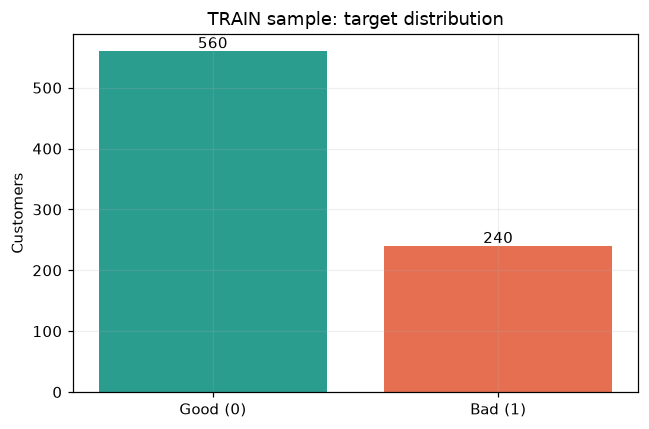

In [84]:
eda=X_train.copy();eda['Target']=y_train
miss=eda.isna().sum().sort_values(ascending=False)
quality=pd.DataFrame({'missing_count':miss,'missing_percent':100*miss/len(eda)})
quality.to_csv(OUT/'missing_quality.csv')
print('TRAIN rows:',len(eda),'Feature count:',X_train.shape[1])
print('Missing total:',int(miss.sum()))
print('Unexpected categorical code count:',sum(bool(v) for v in code_issues.values()))
display(quality.head(12))
print('Target distribution:');display(y_train.value_counts().rename(index={0:'Good',1:'Bad'}).to_frame('Count'))
print('Imbalance ratio Good/Bad=',round(int((y_train==0).sum())/int((y_train==1).sum()),3),' | PR baseline ≈',round(y_train.mean(),3))
fig,ax=plt.subplots(figsize=(6,4));cnt=y_train.value_counts().sort_index()
ax.bar(['Good (0)','Bad (1)'],cnt.values,color=['#2a9d8f','#e76f51'])
for i,v in enumerate(cnt.values):ax.text(i,v+5,str(v),ha='center')
ax.set(title='TRAIN sample: target distribution',ylabel='Customers');plt.tight_layout();plt.savefig(OUT/'01_target_distribution.png',dpi=150);plt.show()


,Q1,Q3,lower,upper,outlier_count,min,max
Credit_Amount,1353.0,3933.0,-2517.0,7803.0,58.0,276.0,15945.0
Duration,12.0,24.0,-6.0,42.0,50.0,4.0,60.0


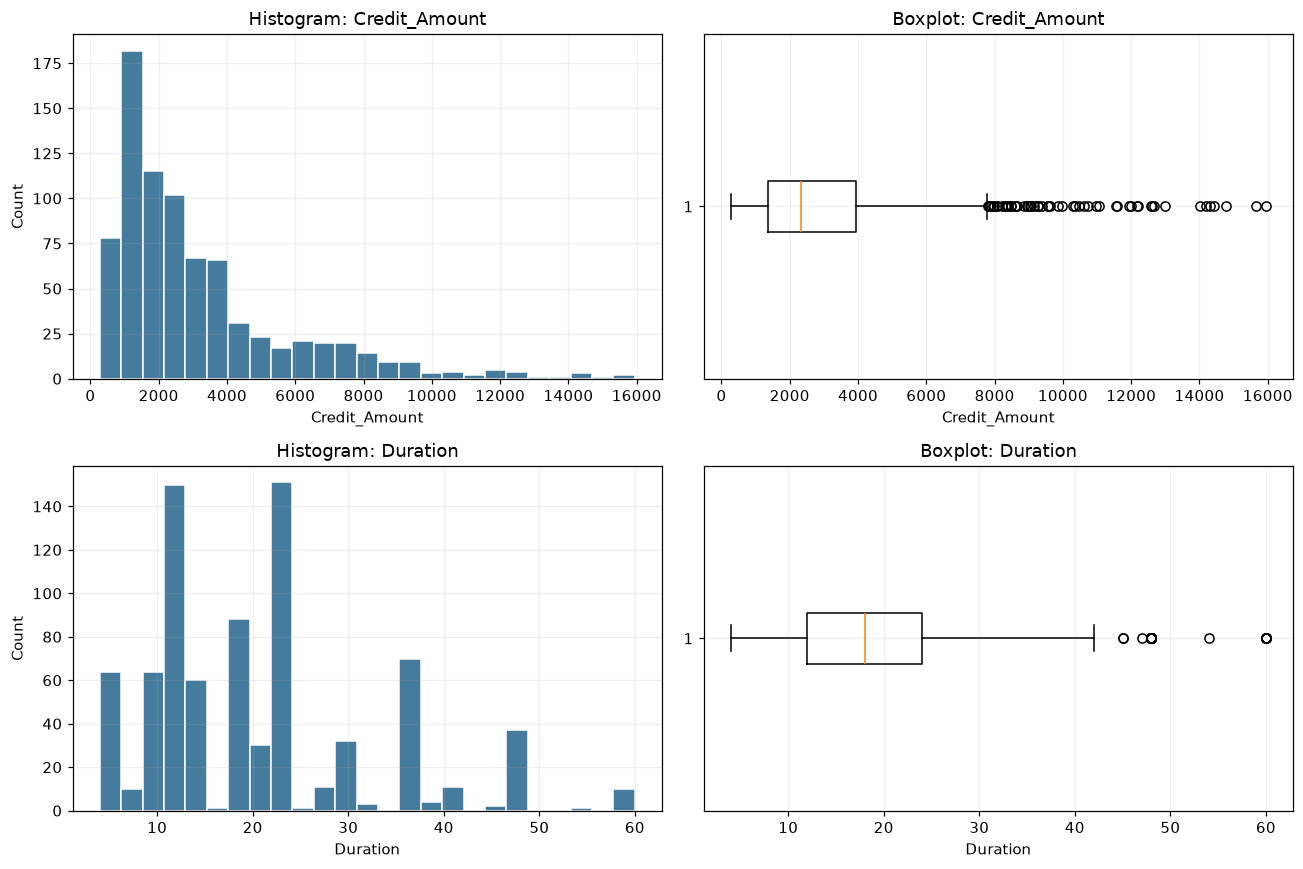

Outliers are investigated, not removed. Duration>0 and Credit_Amount>0 checks:  0 0


In [85]:
# Outlier inspection only: no automatic deletion. IQR thresholds computed on TRAIN for descriptive EDA.
def outlier_iqr(s):
 q1,q3=s.quantile([.25,.75]); iqr=q3-q1
 lo,hi=q1-1.5*iqr,q3+1.5*iqr
 return {'Q1':q1,'Q3':q3,'lower':lo,'upper':hi,'outlier_count':int(((s<lo)|(s>hi)).sum()),'min':s.min(),'max':s.max()}
outlier_table=pd.DataFrame({c:outlier_iqr(eda[c]) for c in ['Credit_Amount','Duration']}).T
display(outlier_table)
fig,axs=plt.subplots(2,2,figsize=(12,8))
for r,c in enumerate(['Credit_Amount','Duration']):
 axs[r,0].hist(eda[c],bins=25,color='#457b9d',edgecolor='white')
 axs[r,0].set(title=f'Histogram: {c}',xlabel=c,ylabel='Count')
 axs[r,1].boxplot(eda[c].dropna(), orientation='horizontal')
 axs[r,1].set(title=f'Boxplot: {c}',xlabel=c)
plt.tight_layout();plt.savefig(OUT/'02_amount_duration_hist_box.png',dpi=160);plt.show()
print('Outliers are investigated, not removed. Duration>0 and Credit_Amount>0 checks: ',
      int((eda.Duration<=0).sum()),int((eda.Credit_Amount<=0).sum()))


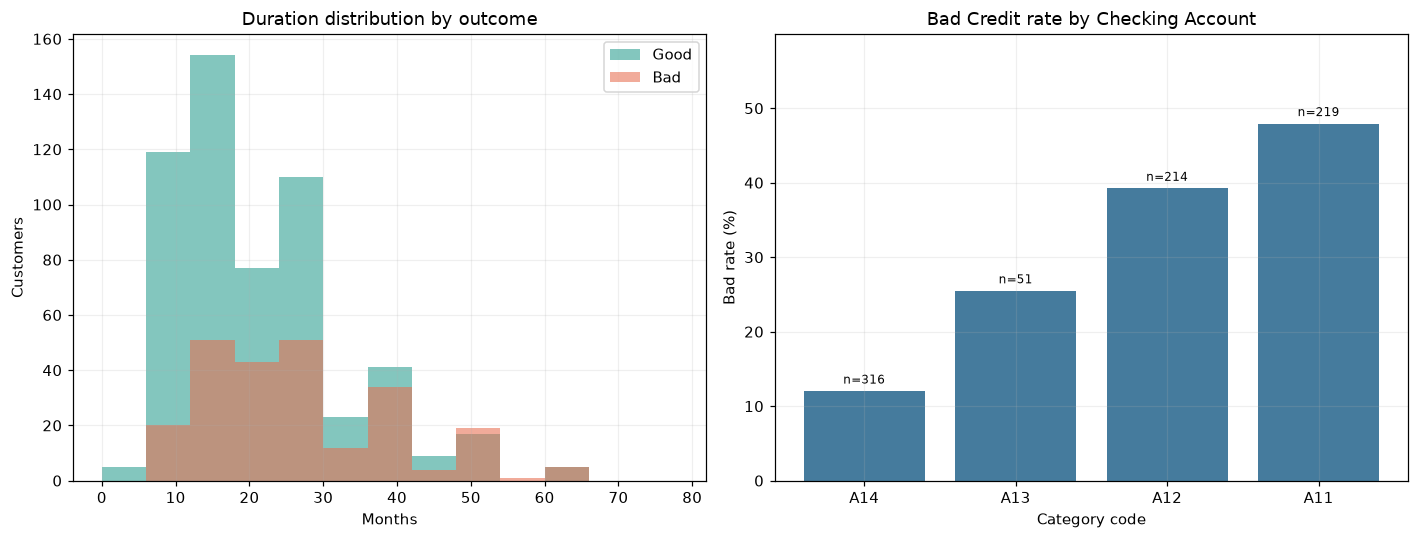

Checking account category table (sample size included):


,mean,size,Bad_Percent
Checking_Account,,,
A14,0.120253,316,12.0
A13,0.254902,51,25.5
A12,0.392523,214,39.3
A11,0.479452,219,47.9


In [86]:
# Core EDA charts linking RAW features with the target (mandatory).
fig,axs=plt.subplots(1,2,figsize=(13,5))
for cl,color,name in [(0,'#2a9d8f','Good'),(1,'#e76f51','Bad')]:
 axs[0].hist(eda.loc[eda.Target==cl,'Duration'],bins=np.arange(0,81,6),alpha=.58,label=name,color=color)
axs[0].set(title='Duration distribution by outcome',xlabel='Months',ylabel='Customers');axs[0].legend()
acc=eda.groupby('Checking_Account')['Target'].agg(['mean','size']).sort_values('mean')
axs[1].bar(acc.index,100*acc['mean'],color='#457b9d')
for k,(cat,row) in enumerate(acc.iterrows()):axs[1].text(k,row['mean']*100+1,f"n={int(row['size'])}",ha='center',fontsize=8)
axs[1].set(title='Bad Credit rate by Checking Account',xlabel='Category code',ylabel='Bad rate (%)',ylim=(0,min(100,max(acc['mean'])*100+12)))
plt.tight_layout();plt.savefig(OUT/'03_two_key_target_plots.png',dpi=180);plt.show()
print('Checking account category table (sample size included):');display(acc.assign(Bad_Percent=(acc['mean']*100).round(1)))


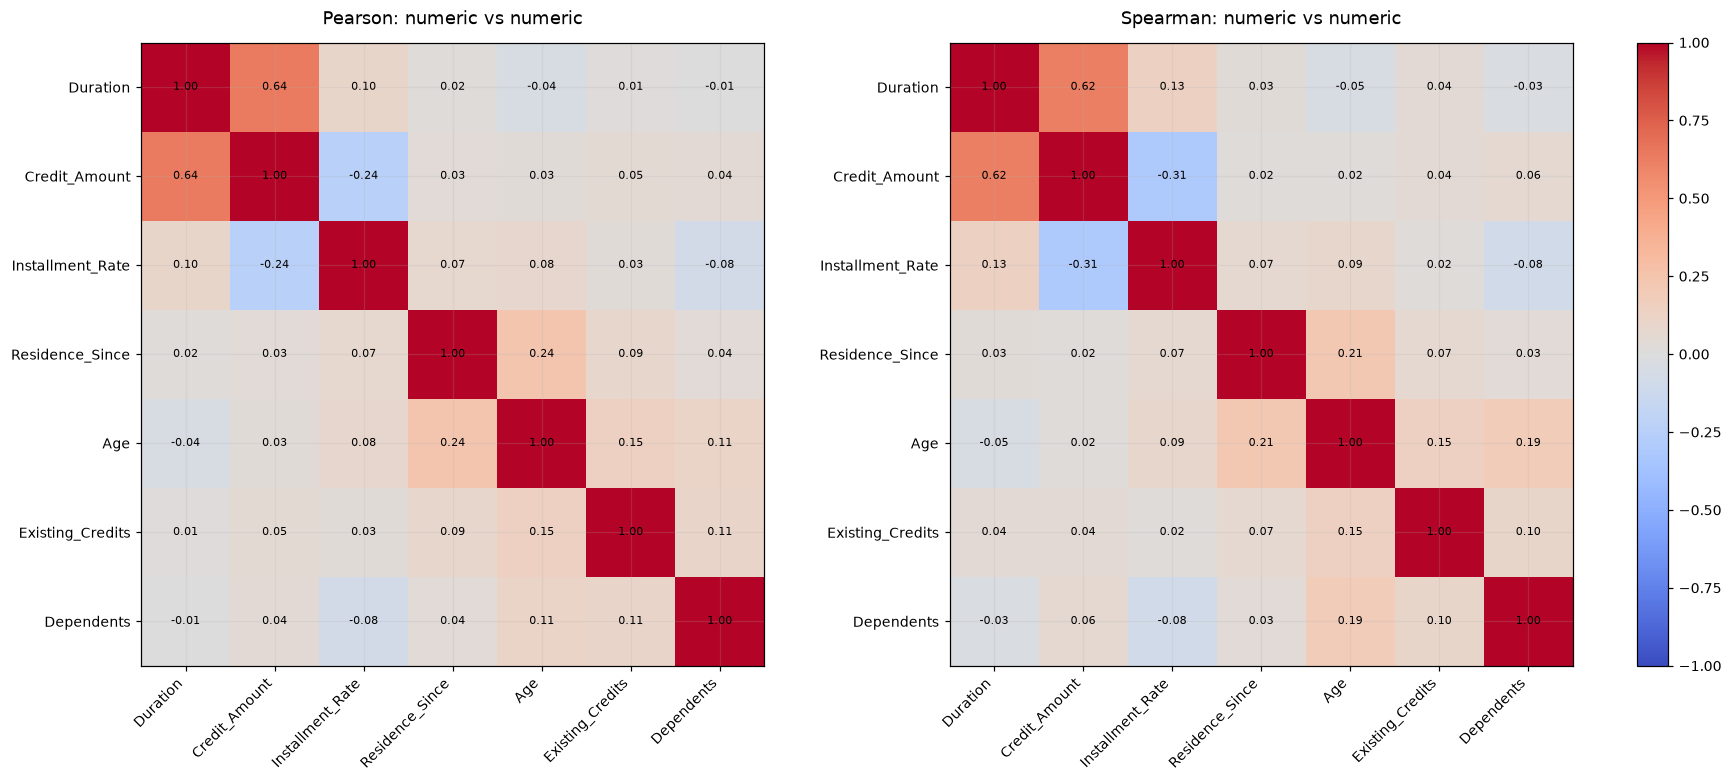

Point-Biserial associations with Bad Target:


,Feature,Point-Biserial r,p-value,Bad_mean,Good_mean
0,Duration,0.2063,0.0000,24.4917,19.1750
1,Credit_Amount,0.1388,0.0001,3755.9875,2946.8500
2,Installment_Rate,0.0803,0.0230,3.0792,2.8821
4,Age,-0.0578,0.1026,34.3500,35.7411
5,Existing_Credits,-0.0471,0.1828,1.3667,1.4250
6,Dependents,0.0119,0.7367,1.1667,1.1571
3,Residence_Since,0.0020,0.9558,2.8333,2.8286


In [87]:
# Number-to-number Pearson/Spearman and number-to-binary point biserial
pear = eda[NUMERIC].corr(method='pearson')
spear = eda[NUMERIC].corr(method='spearman')

point_rows = []
for c in NUMERIC:
    r, p = pointbiserialr(eda['Target'], eda[c])
    point_rows.append({
        'Feature': c,
        'Point-Biserial r': r,
        'p-value': p,
        'Bad_mean': eda.loc[eda.Target == 1, c].mean(),
        'Good_mean': eda.loc[eda.Target == 0, c].mean()
    })

point_tab = pd.DataFrame(point_rows).sort_values(
    'Point-Biserial r', key=abs, ascending=False
)

fig, axs = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)

for ax, mat, title in [
    (axs[0], pear, 'Pearson: numeric vs numeric'),
    (axs[1], spear, 'Spearman: numeric vs numeric')
]:
    im = ax.imshow(mat, vmin=-1, vmax=1, cmap='coolwarm')

    ax.set_title(title, fontsize=12, pad=12)

    ax.set_xticks(np.arange(len(NUMERIC)))
    ax.set_xticklabels(NUMERIC, rotation=45, ha='right', fontsize=9)

    ax.set_yticks(np.arange(len(NUMERIC)))
    ax.set_yticklabels(NUMERIC, fontsize=9)

    # اگر خواستی عدد هر خانه هم دیده شود
    for i in range(len(NUMERIC)):
        for j in range(len(NUMERIC)):
            ax.text(
                j, i, f"{mat.iloc[i, j]:.2f}",
                ha='center', va='center',
                fontsize=7, color='black'
            )

cbar = fig.colorbar(im, ax=axs, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=9)

plt.savefig(OUT / '04_numeric_correlations.png', dpi=200, bbox_inches='tight')
plt.show()

print('Point-Biserial associations with Bad Target:')
display(point_tab.round(4))
point_tab.to_csv(OUT / 'point_biserial.csv', index=False)

,Feature,Cramers_V,Chi_square_p,Min_expected_cell,Smallest_category_n
0,Checking_Account,0.3380,0.0000,15.3,51
1,Credit_History,0.2354,0.0000,9.3,31
3,Savings_Account,0.2026,0.0000,12.3,41
2,Purpose,0.1777,0.0027,1.5,5
7,Property,0.1764,0.0000,37.2,124
4,Employment_Status,0.1660,0.0002,12.3,41
8,Other_Installment_Plans,0.1430,0.0003,11.7,39
9,Housing,0.1388,0.0005,25.8,86
5,Personal_Status_Sex,0.1113,0.0193,12.3,41
12,Foreign_Worker,0.0820,0.0204,9.3,31


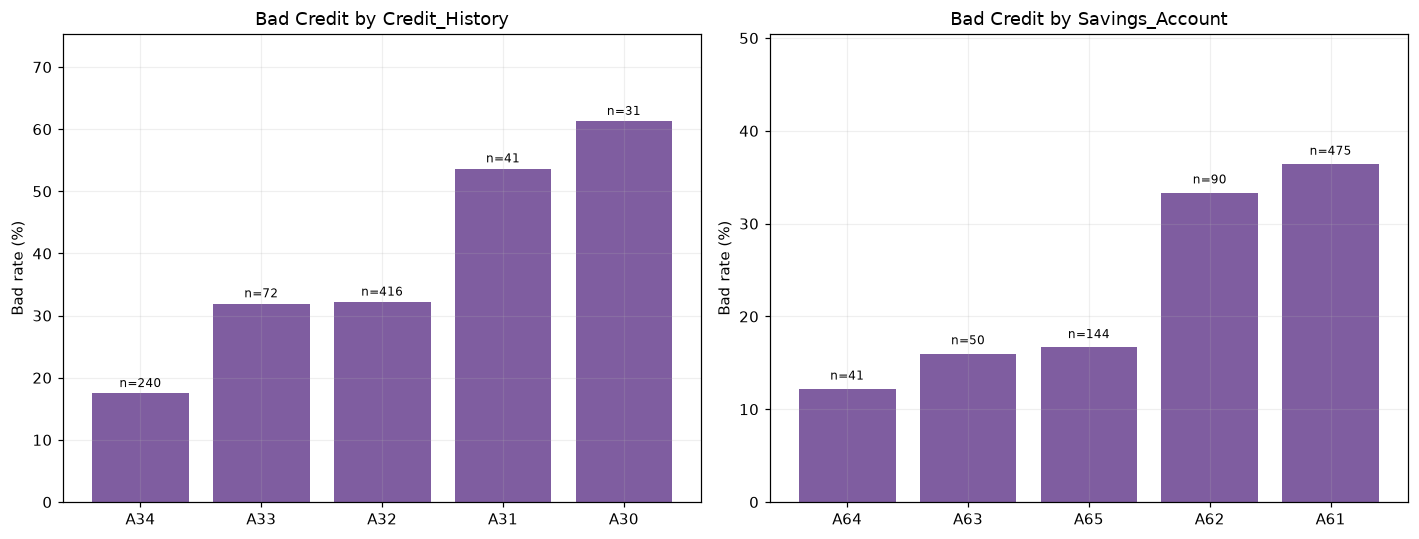

Conditional ordinal trend (special categories excluded): Employment_Status


,size,mean
Employment_Status,,
A72,143,0.440559
A73,271,0.276753
A74,139,0.223022
A75,206,0.262136


Conditional ordinal trend (special categories excluded): Savings_Account


,size,mean
Savings_Account,,
A61,475,0.364211
A62,90,0.333333
A63,50,0.160000
A64,41,0.121951


Conditional ordinal trend (special categories excluded): Checking_Account


,size,mean
Checking_Account,,
A11,219,0.479452
A12,214,0.392523
A13,51,0.254902


In [88]:
# Categorical association: chi-square / Cramer's V + explicit sample counts.
def cramers_v(table):
 chi2,p,dof,expected=chi2_contingency(table)
 n=table.to_numpy().sum();k=min(table.shape)-1
 return float(np.sqrt((chi2/n)/k)) if k>0 else np.nan,float(p),float(expected.min())
cat_rows=[]
for c in CATEGORICAL:
 table=pd.crosstab(eda[c],eda['Target'])
 v,p,minexp=cramers_v(table)
 cat_rows.append({'Feature':c,'Cramers_V':v,'Chi_square_p':p,'Min_expected_cell':minexp,'Smallest_category_n':int(eda[c].value_counts().min())})
cat_assoc=pd.DataFrame(cat_rows).sort_values('Cramers_V',ascending=False)
display(cat_assoc.round(4));cat_assoc.to_csv(OUT/'categorical_associations.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(13,5))
for ax,c in zip(axs,['Credit_History','Savings_Account']):
 tab=eda.groupby(c)['Target'].agg(['mean','size']).sort_values('mean')
 bars=ax.bar(tab.index,100*tab['mean'],color='#7f5da0')
 for i,(_,r) in enumerate(tab.iterrows()):ax.text(i,r['mean']*100+1,f"n={int(r['size'])}",ha='center',fontsize=8)
 ax.set(title=f'Bad Credit by {c}',ylabel='Bad rate (%)',ylim=(0,min(100,100*tab['mean'].max()+14)))
plt.tight_layout();plt.savefig(OUT/'05_categorical_target_rates.png',dpi=170);plt.show()
# Ordered trend only within categories for which meaningful order can be defended.
for c,ordered in [('Employment_Status',['A72','A73','A74','A75']),('Savings_Account',['A61','A62','A63','A64']),('Checking_Account',['A11','A12','A13'])]:
 sub=eda.loc[eda[c].isin(ordered)].groupby(c)['Target'].agg(['size','mean']).reindex(ordered)
 print('Conditional ordinal trend (special categories excluded):',c);display(sub)


In [89]:
# Optional nonlinear signal: mutual information on train-only encodings (illustrative, not selection for model).
mi_frame=X_train.copy()
for c in CATEGORICAL:mi_frame[c]=pd.Categorical(mi_frame[c]).codes
for c in NUMERIC:mi_frame[c]=pd.to_numeric(mi_frame[c])
mi=mutual_info_classif(mi_frame,y_train,discrete_features=[c in CATEGORICAL for c in mi_frame.columns],random_state=RANDOM_STATE)
mi_tab=pd.DataFrame({'Feature':mi_frame.columns,'Mutual_Information':mi}).sort_values('Mutual_Information',ascending=False)
display(mi_tab.head(12).round(5));mi_tab.to_csv(OUT/'mutual_information.csv',index=False)
print('Warning: MI can be unstable in small samples and should not be directly numerically compared to Cramers V or correlations.')


,Feature,Mutual_Information
0,Checking_Account,0.06084
2,Credit_History,0.02732
5,Savings_Account,0.02229
4,Credit_Amount,0.02198
3,Purpose,0.01589
11,Property,0.01534
6,Employment_Status,0.01330
7,Installment_Rate,0.01281
1,Duration,0.01074
17,Dependents,0.01031


## Stage 4 — Domain-informed financial feature engineering

**Objective:** Introduce deterministic predictors that summarize loan structure and employment history, using only attributes available at the assumed application decision time.

### 4.1 — Principal amount per contractual month

$$
\mathrm{Credit\_Amount\_Per\_Month} =
\frac{\mathrm{Credit\_Amount}}{\mathrm{Duration}}
$$

**Interpretation:** A principal-per-month proxy that jointly represents loan size and term. It is **not** a contractual installment, interest-adjusted payment, or debt-to-income ratio: the required interest and income information is not supplied.

### 4.2 — Employment-duration indicator

`Long_Employment` is set to `1` for documented employment categories `A74` and `A75` and to `0` for the other observed valid categories. Missing employment status remains missing for the downstream imputer.

**Interpretation:** A hypothesis about employment continuity, not proof that a longer employment history causally reduces default risk.

### Implementation safeguards

- Convert loan amount and term to numeric values and treat nonpositive values as invalid before constructing the ratio.
- Prevent division-by-zero and infinite derived outputs from propagating into the estimator.
- Keep feature construction independent of `Target` and inside the estimator Pipeline.
- Leave the optional `Missing_Count` feature disabled under the current configuration.

**How to assess utility:** Stage 6 contains a training-only ablation comparison. Its measured metrics are displayed by code and are not hard-coded here. That comparison is exploratory because it follows model tuning.


### 4.3 — Implementation and feature-dependency audit

`LoanFeatureEngineer` implements the derived features as a reusable scikit-learn transformer. The following code displays a feature-dependency map, a small transformed-data preview, and validity checks, then saves the dependency documentation.

**Review:** Verify that the formulas use only available input columns and that invalid divisions are handled safely. The preview values are execution outputs, not fixed study conclusions.


In [90]:
class LoanFeatureEngineer(BaseEstimator, TransformerMixin):
    """Deterministic, point-in-time feature engineering; no target is used."""
    def __init__(self,engineered=True,add_missing_count=False):
        self.engineered=engineered;self.add_missing_count=add_missing_count
    def fit(self,X,y=None):
        self.input_columns_=list(X.columns)
        return self
    def transform(self,X):
        z=pd.DataFrame(X).copy()
        for c in ['Duration','Credit_Amount']:
            z[c]=pd.to_numeric(z[c],errors='coerce')
        if self.add_missing_count:
            z['Missing_Count']=z.isna().sum(axis=1).astype(float) # raw missing before validation
        # treat physically invalid amount/duration as missing; retain all other raw columns
        z.loc[z['Duration']<=0,'Duration']=np.nan
        z.loc[z['Credit_Amount']<=0,'Credit_Amount']=np.nan
        if self.engineered:
            z['Credit_Amount_Per_Month']=z['Credit_Amount']/z['Duration']
            z['Credit_Amount_Per_Month']=z['Credit_Amount_Per_Month'].replace([np.inf,-np.inf],np.nan)
            status=z['Employment_Status']
            z['Long_Employment']=np.where(status.isna(),np.nan,status.isin(['A74','A75']).astype(float))
        return z

dependency=pd.DataFrame([
 {'Feature':'Credit_Amount_Per_Month','Formula':'Credit_Amount / Duration','Requires':'Credit_Amount > 0, Duration > 0','Order':'validate inputs → compute ratio → handle invalid output','Meaning':'principal per month, NOT contractual installment'},
 {'Feature':'Long_Employment','Formula':'1 if status in A74/A75 else 0','Requires':'documented employment codes','Order':'decode raw codes → flag → encode categories','Meaning':'at least 4 years employed; hypothesis only'},
 {'Feature':'Missing_Count [not used]','Formula':'count of original NaNs','Requires':'missingness actually exists','Order':'count raw NaNs → impute','Meaning':'constant zero on supplied data'}])
display(dependency);dependency.to_csv(OUT/'feature_dependency_map.csv',index=False)
feature_demo=LoanFeatureEngineer().fit_transform(X_train)
display(feature_demo[['Credit_Amount','Duration','Credit_Amount_Per_Month','Employment_Status','Long_Employment']].head(6))
print('Financial feature infinities:',int(np.isinf(feature_demo['Credit_Amount_Per_Month']).sum()))


,Feature,Formula,Requires,Order,Meaning
0,Credit_Amount_Per_Month,Credit_Amount / Duration,"Credit_Amount > 0, Duration > 0",validate inputs → compute ratio → handle inval...,"principal per month, NOT contractual installment"
1,Long_Employment,1 if status in A74/A75 else 0,documented employment codes,decode raw codes → flag → encode categories,at least 4 years employed; hypothesis only
2,Missing_Count [not used],count of original NaNs,missingness actually exists,count raw NaNs → impute,constant zero on supplied data


,Credit_Amount,Duration,Credit_Amount_Per_Month,Employment_Status,Long_Employment
828,8335.0,36.0,231.527778,A75,1.0
997,804.0,12.0,67.000000,A75,1.0
148,5371.0,36.0,149.194444,A73,0.0
735,3990.0,36.0,110.833333,A72,0.0
130,8487.0,48.0,176.812500,A74,1.0
654,2346.0,24.0,97.750000,A74,1.0


Financial feature infinities: 0


## Stage 5 — Fold-local preprocessing Pipeline

**Objective:** Convert the raw and engineered inputs into a representation suitable for tree-based estimators while avoiding preprocessing leakage.

| Pipeline component | Implementation and intent |
|:--|:--|
| `LoanFeatureEngineer` | Construct derived columns deterministically; no target-derived fitting |
| Numerical imputation | `SimpleImputer(strategy='median')`, learned from the training fold |
| Categorical imputation | `SimpleImputer(strategy='most_frequent')`, learned from the training fold |
| Categorical encoding | `OneHotEncoder(handle_unknown='ignore')`; vocabulary fitted on training categories |
| Numerical scaling | Optional; bypassed under the current tree-model defaults |
| Random oversampling | Optional Pipeline step; not enabled in the default model configuration |
| IQR capping | Transformer defined for possible experiments, but not inserted into the active Pipeline |

**Why one-hot encoding?** Codes such as `A11` and `A14` are category identifiers, not numerical quantities with meaningful distances. Documented categories `A14` and `A65` are preserved as valid levels rather than reclassified as missing.

**Leakage safeguard:** During CV, fitted preprocessing learns statistics and categories from each training fold. Any enabled oversampling is performed on that fold's training subset only, never on validation or Test records.

**Verification:** A small training-only smoke test checks the Pipeline interface and probability output shape. Passing the smoke test establishes *technical functionality*, not predictive quality.


### 5.1 — Construct and smoke-test the Pipeline

The next cell defines the numeric/categorical preprocessors, an optional IQR-capping transformer, and `make_pipeline()` for assembling feature engineering, preprocessing, optional resampling, and an estimator.

**Execution distinction:** Defining the optional capping class does not activate it. Creating a Pipeline does not train it. The `toy.fit(...)` call runs a small training-only test, followed by `predict_proba(...)` and validity assertions. Formal model evaluation begins in Stage 6.


In [91]:
NUMERIC_ENH=NUMERIC+['Credit_Amount_Per_Month','Long_Employment']

def build_preprocessor(engineered=True,scale=False):
    nums=NUMERIC_ENH if engineered else NUMERIC
    # A14/no checking and A65/unknown-no-savings are legitimate categories, not missing.
    numeric_pipeline=Pipeline([('impute',SimpleImputer(strategy='median')),
                                ('scale',StandardScaler() if scale else 'passthrough')])
    categorical_pipeline=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                                    ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
    return ColumnTransformer([('num',numeric_pipeline,nums),('cat',categorical_pipeline,CATEGORICAL)],remainder='drop',sparse_threshold=0)

class IQRCapper(BaseEstimator,TransformerMixin):
    """Optional learned outlier capping. NOT used by default; justified only after validation."""
    def __init__(self,columns=('Credit_Amount','Duration'),factor=1.5):self.columns=columns;self.factor=factor
    def fit(self,X,y=None):
        z=pd.DataFrame(X);self.bounds_={}
        for c in self.columns:
            q1,q3=z[c].quantile([.25,.75]);d=q3-q1
            self.bounds_[c]=(q1-self.factor*d,q3+self.factor*d)
        return self
    def transform(self,X):
        z=pd.DataFrame(X).copy()
        for c,(lo,hi) in self.bounds_.items():z[c]=z[c].clip(lo,hi)
        return z

def make_pipeline(estimator,engineered=True,resample=False,scale=False):
    return ImbPipeline([
        ('domain',LoanFeatureEngineer(engineered=engineered,add_missing_count=False)),
        ('preprocess',build_preprocessor(engineered=engineered,scale=scale)),
        ('sampler',RandomOverSampler(random_state=RANDOM_STATE) if resample else 'passthrough'),
        ('model',estimator)])

# Fit on a small TRAIN subset solely for schema/unit-test purposes; not reused for reported CV scores.
toy=make_pipeline(DecisionTreeClassifier(max_depth=2,random_state=RANDOM_STATE))
toy.fit(X_train.iloc[:100],y_train.iloc[:100]);pred=toy.predict_proba(X_train.iloc[100:105])[:,1]
assert np.isfinite(pred).all() and len(pred)==5
print('Pipeline smoke test: PASS | output examples:',np.round(pred,4))
print('Imputation guard exists for future missing inputs; actual data contained 0 missing values.')
print('Scaling not applied to tree models; feature selection not yet used; capping OFF by default.')


Pipeline smoke test: PASS | output examples: [0.1132 0.7692 0.3214 0.7692 0.1132]
Imputation guard exists for future missing inputs; actual data contained 0 missing values.
Scaling not applied to tree models; feature selection not yet used; capping OFF by default.


## Stage 6 — Model benchmark and hyperparameter selection

**Objective:** Compare an interpretable Decision Tree baseline with a Random Forest challenger using training-only cross-validation. The estimators share the same feature engineering and preprocessing strategy.

### Tuning protocol

- Construct both estimator Pipelines using `make_pipeline()`.
- Define search spaces for tree depth, minimum samples per leaf, and class weighting.
- Use stratified `GridSearchCV` to evaluate each hyperparameter combination.
- Compute **ROC-AUC**, **Average Precision (AP)**, and **balanced accuracy**; use **mean validation AP** as the predeclared selection objective.
- Refit the best configuration of each model family on the full training partition.
- Compare the selected configurations and retain a fresh, unfitted clone of the chosen Pipeline for later stages.

**What to inspect:** The next output reports the winning family, its tuned hyperparameters, and cross-validated performance. These are **execution-dependent** and intentionally not stated in Markdown.

**Statistical caution:** The winning GridSearchCV score can be optimistic because it is also used to select the winner. Stage 7 applies repeated nested validation to assess the wider selection procedure without using the historical Test.


### 6.1 — Run the parameter searches

The next code cell defines the metric dictionary, candidate Pipelines, and parameter grids; then `.fit(...)` executes cross-validated hyperparameter searches for both model families.

**Interpret the table:** `CV ROC-AUC` and `CV PR-AUC (AP)` describe validation ranking performance; `CV AP SD` summarizes variability across selection folds; and `Best parameters` lists the configuration that achieved the highest mean AP among the candidates.

**Boundary:** The historical Test is excluded. Model family and hyperparameters are chosen from Train only.


In [92]:
scoring={'roc_auc':'roc_auc','ap':'average_precision','balanced_acc':'balanced_accuracy'}
dt=make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))
rf=make_pipeline(RandomForestClassifier(n_estimators=120,n_jobs=1,random_state=RANDOM_STATE))
dt_grid={'model__max_depth':[2,3,4], 'model__min_samples_leaf':[15,30], 'model__class_weight':[None,'balanced']}
rf_grid={'model__max_depth':[5,None], 'model__min_samples_leaf':[5,12], 'model__class_weight':[None,'balanced']}
dt_search=GridSearchCV(dt,dt_grid,scoring=scoring,refit='ap',cv=selection_cv,n_jobs=1,return_train_score=True)
rf_search=GridSearchCV(rf,rf_grid,scoring=scoring,refit='ap',cv=selection_cv,n_jobs=1,return_train_score=True)
dt_search.fit(X_train,y_train)
rf_search.fit(X_train,y_train)
cv_table=pd.DataFrame([{'Model':'Decision Tree','CV ROC-AUC':dt_search.cv_results_['mean_test_roc_auc'][dt_search.best_index_],
 'CV PR-AUC (AP)':dt_search.best_score_,'CV AP SD':dt_search.cv_results_['std_test_ap'][dt_search.best_index_],
 'Best parameters':str(dt_search.best_params_)},
 {'Model':'Random Forest','CV ROC-AUC':rf_search.cv_results_['mean_test_roc_auc'][rf_search.best_index_],
 'CV PR-AUC (AP)':rf_search.best_score_,'CV AP SD':rf_search.cv_results_['std_test_ap'][rf_search.best_index_],
 'Best parameters':str(rf_search.best_params_)}])
display(cv_table);cv_table.to_csv(OUT/'cv_model_comparison.csv',index=False)
# Choosing by PREDECLARED validation objective: mean Average Precision (class=1 Bad)
selected_name=str(cv_table.sort_values('CV PR-AUC (AP)',ascending=False).iloc[0]['Model'])
selected_search=rf_search if selected_name=='Random Forest' else dt_search
selected_estimator=clone(selected_search.best_estimator_)
print('Train-only final model selection BEFORE Test:',selected_name,'best params',selected_search.best_params_)


,Model,CV ROC-AUC,CV PR-AUC (AP),CV AP SD,Best parameters
0,Decision Tree,0.731579,0.484528,0.069575,"{'model__class_weight': None, 'model__max_dept..."
1,Random Forest,0.793245,0.610559,0.075204,"{'model__class_weight': None, 'model__max_dept..."


Train-only final model selection BEFORE Test: Random Forest best params {'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 5}


In [93]:
# Additional (optional) imbalance comparison: class weights in grid and RandomOverSampler inside folds.
ros_model=clone(selected_search.best_estimator_)
ros_model.set_params(sampler=RandomOverSampler(random_state=RANDOM_STATE))
# do not stack class weighting on top of resampling in this controlled comparison
ros_model.set_params(model__class_weight=None)
ros_scores=cross_validate(ros_model,X_train,y_train,cv=cv,scoring=scoring,n_jobs=1)
imbalance_comparison=pd.DataFrame([
 {'Method':'Selected model (CV tuning)','ROC-AUC':float(cv_table.loc[cv_table.Model==selected_name,'CV ROC-AUC'].iloc[0]),'AP':selected_search.best_score_},
 {'Method':'RandomOverSampler within train folds (illustrative)','ROC-AUC':ros_scores['test_roc_auc'].mean(),'AP':ros_scores['test_ap'].mean()}])
display(imbalance_comparison)
print('Resampling is an exploratory comparison, not automatically selected just because dataset is 70/30.')


,Method,ROC-AUC,AP
0,Selected model (CV tuning),0.793245,0.610559
1,RandomOverSampler within train folds (illustra...,0.788876,0.623897


Resampling is an exploratory comparison, not automatically selected just because dataset is 70/30.


In [94]:
# Ablation study: compare raw-only inputs with two engineered features; same CV/algorithm/hyperparameters.
raw_only=clone(selected_search.best_estimator_)
raw_only.set_params(domain__engineered=False,preprocess=build_preprocessor(engineered=False))
plus_engineered=clone(selected_search.best_estimator_)
raw_scores=cross_validate(raw_only,X_train,y_train,cv=cv,scoring=scoring)
eng_scores=cross_validate(plus_engineered,X_train,y_train,cv=cv,scoring=scoring)
ablation=pd.DataFrame([
 {'Features':'Raw 20','CV ROC-AUC':raw_scores['test_roc_auc'].mean(),'CV AP':raw_scores['test_ap'].mean()},
 {'Features':'Raw + engineered 2','CV ROC-AUC':eng_scores['test_roc_auc'].mean(),'CV AP':eng_scores['test_ap'].mean()}])
display(ablation);ablation.to_csv(OUT/'feature_ablation.csv',index=False)
print('Caution: this exploratory comparison follows model selection; it is not an independent unbiased performance estimate.')


,Features,CV ROC-AUC,CV AP
0,Raw 20,0.786086,0.608621
1,Raw + engineered 2,0.794866,0.635128


Caution: this exploratory comparison follows model selection; it is not an independent unbiased performance estimate.


### 6.2 — Supplementary imbalance and feature-ablation experiments

This subsection asks two *separate* exploratory questions:

| Experiment | What changes? | What remains fixed? | What the result can support |
|:--|:--|:--|:--|
| **Oversampling sensitivity** | Enable `RandomOverSampler` within the training folds; use ordinary class weights | Selected model family and tuned hyperparameters | Whether resampling merits further controlled study |
| **Feature ablation** | Compare original predictors with the same predictors plus both engineered features | Selected model family, hyperparameters, and CV scheme | Whether the *combined* engineered feature set appears useful |

**Important comparison limitation:** The displayed oversampling table combines a model-selection CV summary with a separately evaluated resampling variant. These are **not identical validation protocols**; do not attribute any numerical difference solely to oversampling. A controlled baseline and resampled variant would need the same CV splits.

**Ablation limitation:** Both engineered features are added together, so the experiment does **not** isolate the contribution of either feature. The comparison is also performed after model selection on the training data; treat it as exploratory rather than an independent performance estimate.

Read the computed tables for observed metric values. Neither auxiliary analysis automatically changes the chosen model or determines the cost-sensitive classification cut-off.


## Stage 7 — Univariate evidence, nested validation, calibration, and decision threshold

### 7.1 — Identify influential original predictors without using model-specific attributions

The code evaluates each original predictor individually using a simple logistic model and **training-only out-of-fold (OOF)** ROC-AUC and AP. It reports the highest-ranked original predictors and their documented meanings.

**Interpretation:** This is a *univariate* comparison: it does not show incremental importance within the final multivariable estimator, does not remove features from that estimator, and does not establish causality. The identities, ranks, and metric values of the leading predictors are generated by the next code cell rather than fixed in prose.

### 7.2 — Evaluate the full selection procedure with repeated nested CV

The nested assessment separates **decisions** from **evaluation**:

1. An **outer** validation subset is held out.
2. Within the remaining outer-training data, an **inner** procedure reselects the model family and hyperparameters using AP.
3. Training-only cross-fitted probabilities support selection of a cost-sensitive threshold.
4. Sigmoid probability calibration is fitted using training-only splits.
5. The fitted policy is evaluated on the untouched outer-validation subset.
6. The routine repeats this process across the configured outer folds and repeats.

The threshold minimizes the documented benchmark cost:

$$
L(t) = C_{FP}\,FP(t) + C_{FN}\,FN(t)
$$

The implementation's candidate grid and tie-break policy are defined in code. The *selected* threshold may change across executions; do not infer it from the theoretical loss ratio.

**Uncertainty:** Repeated outer folds overlap. Their standard deviations are descriptive across these runs, **not** confidence intervals based on independent samples.

### 7.3 — Choose and freeze a final training-only policy

After nested assessment, a separate training-only OOF procedure produces held-out predictions while reselecting the model within each training fold. These probabilities are used to select the final threshold. The selected Pipeline is then calibrated/fitted on the full training partition and frozen **before any historical Test prediction**.

**Caveat:** Refit and calibration on the full training sample can shift probabilities relative to fold-level OOF models. A training-optimized threshold is not guaranteed to be optimal for future populations.


### 7.4 — Validation flow and leakage safeguards

```text
Original labeled dataset
        |
        +--> Training partition
        |        |
        |        +--> Repeated OUTER CV
        |        |      +--> Outer training: tune model, calibrate, select cutoff
        |        |      +--> Outer validation: evaluate the frozen fold-specific rule
        |        |
        |        +--> Separate training-only OOF pass
        |               +--> Reselect model within each training fold
        |               +--> Generate held-out probabilities
        |               +--> Select final relative-cost cutoff
        |               +--> Fit/calibrate final model on all Train; freeze
        |
        +--> Historical Test: evaluation only after freeze
```

**Safeguards to verify in execution:** The held-out outer fold is excluded from its model and cut-off decisions. The historical Test is not used for tuning, calibration, or threshold choice. Stage 8 reuses the frozen fitted estimator without refitting it.

**Output guide:** The next cells export outer-fold metrics, cut-off stability, OOF calibration comparisons, and the final training-only threshold search. Read all numerical summaries from those artifacts.


In [95]:
# Comparative univariate predictive discrimination for mixed types, without selecting model input columns.
def feature_univariate_auc(feature):
    kind='num' if feature in NUMERIC else 'cat'
    if kind=='num':pr=Pipeline([('imp',SimpleImputer(strategy='median')),('scale',StandardScaler())])
    else:pr=Pipeline([('imp',SimpleImputer(strategy='most_frequent')),
                      ('oh',OneHotEncoder(handle_unknown='ignore'))])
    cp=ColumnTransformer([(kind,pr,[feature])])
    estimator=Pipeline([('col',cp),('lr',LogisticRegression(max_iter=1500,random_state=RANDOM_STATE))])
    oof=cross_val_predict(estimator,X_train[[feature]],y_train,cv=cv,method='predict_proba')[:,1]
    return roc_auc_score(y_train,oof),average_precision_score(y_train,oof)
univar=pd.DataFrame([{'Feature':c,'OOF univariate ROC-AUC':feature_univariate_auc(c)[0],
                      'OOF univariate AP':feature_univariate_auc(c)[1]} for c in COLS[:-1]]).sort_values('OOF univariate ROC-AUC',ascending=False)
TOP3=univar.head(3).Feature.tolist()
print('Top-3 RAW features by comparable univariate OOF ROC-AUC (NOT feature selection for fitted model):',TOP3)
display(univar.head(10));univar.to_csv(OUT/'top_three_and_univariate_scores.csv',index=False)
print('Domain interpretations of the top-3:')
for c in TOP3:print('-',c,':',FEATURE_DESC[c])


Top-3 RAW features by comparable univariate OOF ROC-AUC (NOT feature selection for fitted model): ['Checking_Account', 'Duration', 'Credit_History']


,Feature,OOF univariate ROC-AUC,OOF univariate AP
0,Checking_Account,0.685346,0.425503
1,Duration,0.626399,0.401365
2,Credit_History,0.595290,0.378413
11,Property,0.573300,0.353837
6,Employment_Status,0.567094,0.351778
5,Savings_Account,0.564066,0.329092
3,Purpose,0.554557,0.337279
14,Housing,0.548471,0.329365
4,Credit_Amount,0.546830,0.381214
12,Age,0.544706,0.340758


Domain interpretations of the top-3:
- Checking_Account : Status of existing checking account (A14=no checking account)
- Duration : Credit duration (months)
- Credit_History : Historical account/credit patterns


Outer fold 01/10: Random Forest; threshold=0.1667; FP=66, FN=4, cost/160=0.537
Outer fold 02/10: Random Forest; threshold=0.1667; FP=52, FN=6, cost/160=0.512
Outer fold 03/10: Random Forest; threshold=0.1500; FP=71, FN=2, cost/160=0.506
Outer fold 04/10: Random Forest; threshold=0.1667; FP=51, FN=6, cost/160=0.506
Outer fold 05/10: Random Forest; threshold=0.1750; FP=64, FN=10, cost/160=0.713
Outer fold 06/10: Random Forest; threshold=0.1250; FP=70, FN=5, cost/160=0.594
Outer fold 07/10: Random Forest; threshold=0.1500; FP=66, FN=4, cost/160=0.537
Outer fold 08/10: Random Forest; threshold=0.1500; FP=63, FN=4, cost/160=0.519
Outer fold 09/10: Random Forest; threshold=0.1750; FP=57, FN=9, cost/160=0.637
Outer fold 10/10: Random Forest; threshold=0.1750; FP=56, FN=7, cost/160=0.569

Nested OUTER validation (all Test rows excluded):


,outer_fold,selected_model,cutoff,FP,FN,relative_cost,cost_per_customer,AP,Brier
0,1,Random Forest,0.1667,66,4,86,0.5375,0.6072,0.1665
1,2,Random Forest,0.1667,52,6,82,0.5125,0.6398,0.1608
2,3,Random Forest,0.1500,71,2,81,0.5062,0.6948,0.1505
3,4,Random Forest,0.1667,51,6,81,0.5062,0.5786,0.1686
4,5,Random Forest,0.1750,64,10,114,0.7125,0.6091,0.1775
5,6,Random Forest,0.1250,70,5,95,0.5938,0.6753,0.1568
6,7,Random Forest,0.1500,66,4,86,0.5375,0.5478,0.1749
7,8,Random Forest,0.1500,63,4,83,0.5188,0.5877,0.1655
8,9,Random Forest,0.1750,57,9,102,0.6375,0.6142,0.1743
9,10,Random Forest,0.1750,56,7,91,0.5688,0.7209,0.1565


,metric,mean,SD_across_non_independent_folds,minimum,maximum
0,cutoff,0.1600,0.0161,0.1250,0.1750
1,relative_cost,90.1000,10.8161,81.0000,114.0000
2,cost_per_customer,0.5631,0.0676,0.5062,0.7125
3,FP,61.6000,7.1678,51.0000,71.0000
4,FN,5.7000,2.4518,2.0000,10.0000
5,ROC-AUC,0.7873,0.0237,0.7403,0.8222
6,AP,0.6275,0.0547,0.5478,0.7209
7,Brier,0.1652,0.0090,0.1505,0.1775


Important: repeated validation folds overlap; SD is descriptive and NOT an independent-fold confidence interval.


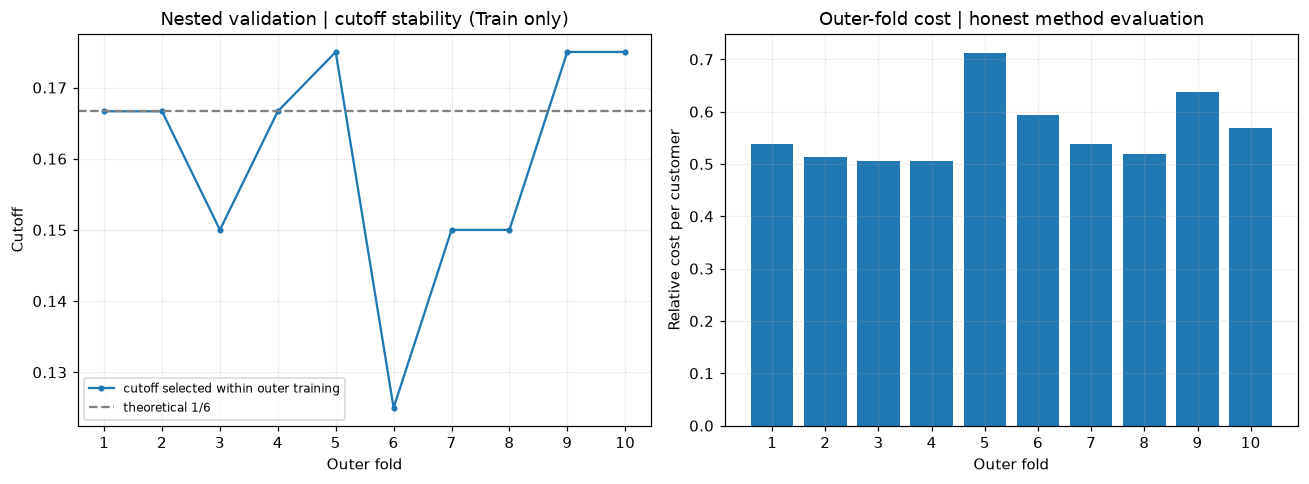

The outer fold was NOT used to choose its model, calibrator, hyperparameters or cutoff.


In [96]:
# Stage 7 — STRICT training-only repeated nested validation for model/calibration/cutoff.
# No Test labels or probabilities are accessed anywhere in this section.
from sklearn.model_selection import RepeatedStratifiedKFold

COST_FP=1
COST_FN=5
THEORETICAL_COST_CUTOFF=COST_FP/(COST_FP+COST_FN)  # 1/6, only Bayes-optimal under stated assumptions
THRESHOLD_GRID=np.unique(np.round(np.r_[np.arange(.05,.701,.025),THEORETICAL_COST_CUTOFF],6))
INNER_SELECTION_FOLDS=3
CALIBRATION_FOLDS=3
OUTER_FOLDS=5
OUTER_REPEATS=2
FINAL_OOF_FOLDS=5

# Same families, preprocessing and hyperparameter search space as Stage 6; all fitted from scratch per training fold.
def select_estimator_train_only(X_fit,y_fit,seed):
    local_cv=StratifiedKFold(n_splits=INNER_SELECTION_FOLDS,shuffle=True,random_state=seed)
    searches=[]
    for title,est,grid in [('Decision Tree',dt,dt_grid),('Random Forest',rf,rf_grid)]:
        search=GridSearchCV(clone(est),grid,scoring='average_precision',refit=True,cv=local_cv,n_jobs=1)
        search.fit(X_fit,y_fit)
        searches.append((title,search))
    # AP primary. In an exact tie, favor simpler Decision Tree (fixed deterministic ordering).
    selected_title,selected_search=max(searches,key=lambda item:(item[1].best_score_,-(item[0]=='Random Forest')))
    return clone(selected_search.best_estimator_),selected_title,float(selected_search.best_score_),selected_search.best_params_

def calibrated_fit_train_only(estimator,X_fit,y_fit,seed):
    cal_cv=StratifiedKFold(n_splits=CALIBRATION_FOLDS,shuffle=True,random_state=seed)
    model=CalibratedClassifierCV(estimator=clone(estimator),method='sigmoid',cv=cal_cv,ensemble=False)
    model.fit(X_fit,y_fit)
    return model

def training_only_oof(X_fit,y_fit,n_folds,seed):
    """OOF: EACH fold chooses family + params and fits calibration on its own training portion."""
    x=X_fit.reset_index(drop=True)
    y_local=y_fit.reset_index(drop=True)
    fold_cv=StratifiedKFold(n_splits=n_folds,shuffle=True,random_state=seed)
    probs=np.full(len(x),np.nan)
    raw_probs=np.full(len(x),np.nan)
    fold_log=[]
    for fold,(fit_idx,val_idx) in enumerate(fold_cv.split(x,y_local),1):
        assert not set(fit_idx).intersection(val_idx)
        x_fit,y_fit_local=x.iloc[fit_idx],y_local.iloc[fit_idx]
        x_val=x.iloc[val_idx]
        best,name,ap,params=select_estimator_train_only(x_fit,y_fit_local,seed+fold*47)
        cal=calibrated_fit_train_only(best,x_fit,y_fit_local,seed+fold*53)
        raw=clone(best).fit(x_fit,y_fit_local)
        probs[val_idx]=cal.predict_proba(x_val)[:,1]
        raw_probs[val_idx]=raw.predict_proba(x_val)[:,1]
        fold_log.append({'fold':fold,'n_train':len(fit_idx),'n_validation':len(val_idx),
                         'selected_model':name,'inner_cv_ap':ap,'params':str(params)})
    assert np.isfinite(probs).all() and np.isfinite(raw_probs).all()
    assert ((probs>=0)&(probs<=1)).all()
    return probs,raw_probs,pd.DataFrame(fold_log)

def cutoff_cost_table(y_actual,probs):
    yt=np.asarray(y_actual,dtype=int)
    records=[]
    for th in THRESHOLD_GRID:
        pred=(np.asarray(probs)>=th).astype(int)
        tn,fp,fn,tp=confusion_matrix(yt,pred,labels=[0,1]).ravel()
        records.append({'threshold':float(th),'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
                        'relative_cost':int(COST_FP*fp+COST_FN*fn),'cost_per_customer':(COST_FP*fp+COST_FN*fn)/len(yt)})
    return pd.DataFrame(records)

def cutoff_from_training_only_oof(y_actual,probs):
    table=cutoff_cost_table(y_actual,probs)
    ordered=table.assign(theoretical_distance=(table.threshold-THEORETICAL_COST_CUTOFF).abs())                 .sort_values(['relative_cost','theoretical_distance','threshold'],kind='stable').reset_index(drop=True)
    return float(ordered.loc[0,'threshold']),table,ordered

outer_rows=[]
outer_cutoff_tables=[]
outer_folds=RepeatedStratifiedKFold(n_splits=OUTER_FOLDS,n_repeats=OUTER_REPEATS,random_state=RANDOM_STATE+500)
for outer_id,(outer_fit,outer_val) in enumerate(outer_folds.split(X_train,y_train),1):
    assert set(outer_fit).isdisjoint(outer_val)
    x_fit,y_fit=X_train.iloc[outer_fit],y_train.iloc[outer_fit]
    x_val,y_val=X_train.iloc[outer_val],y_train.iloc[outer_val]
    inner_probs,_,inner_folds=training_only_oof(x_fit,y_fit,n_folds=3,seed=2000+outer_id*31)
    chosen,tab,_=cutoff_from_training_only_oof(y_fit,inner_probs)
    tab['outer_fold']=outer_id
    outer_cutoff_tables.append(tab)
    best,name,cv_ap,params=select_estimator_train_only(x_fit,y_fit,seed=3000+outer_id*31)
    model=calibrated_fit_train_only(best,x_fit,y_fit,seed=4000+outer_id*31)
    outer_prob=model.predict_proba(x_val)[:,1]
    tn,fp,fn,tp=confusion_matrix(y_val,(outer_prob>=chosen).astype(int),labels=[0,1]).ravel()
    outer_rows.append({'outer_fold':outer_id,'repeat':1+(outer_id-1)//OUTER_FOLDS,
                       'n_train':len(outer_fit),'n_validation':len(outer_val),
                       'selected_model':name,'cutoff':chosen,'inner_cv_ap':cv_ap,
                       'AP':average_precision_score(y_val,outer_prob),'ROC-AUC':roc_auc_score(y_val,outer_prob),
                       'Brier':brier_score_loss(y_val,outer_prob),
                       'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
                       'relative_cost':int(COST_FP*fp+COST_FN*fn),
                       'cost_per_customer':(COST_FP*fp+COST_FN*fn)/len(outer_val),
                       'selected_parameters':str(params)})
    print(f'Outer fold {outer_id:02d}/{OUTER_FOLDS*OUTER_REPEATS}: {name}; threshold={chosen:.4f}; '
          f'FP={fp}, FN={fn}, cost/{len(outer_val)}={(COST_FP*fp+COST_FN*fn)/len(outer_val):.3f}',flush=True)

nested_outer_results=pd.DataFrame(outer_rows)
nested_outer_cutoff_costs=pd.concat(outer_cutoff_tables,ignore_index=True)
assert len(nested_outer_results)==OUTER_FOLDS*OUTER_REPEATS
nested_outer_results.to_csv(OUT/'nested_outer_fold_results.csv',index=False)
nested_outer_cutoff_costs.to_csv(OUT/'nested_outer_training_cutoff_costs.csv',index=False)
nested_outer_summary=pd.DataFrame([{'metric':m,'mean':nested_outer_results[m].mean(),
                                    'SD_across_non_independent_folds':nested_outer_results[m].std(ddof=1),
                                    'minimum':nested_outer_results[m].min(),'maximum':nested_outer_results[m].max()}
                                   for m in ['cutoff','relative_cost','cost_per_customer','FP','FN','ROC-AUC','AP','Brier']])
nested_outer_summary.to_csv(OUT/'nested_outer_summary.csv',index=False)
print('\nNested OUTER validation (all Test rows excluded):')
display(nested_outer_results[['outer_fold','selected_model','cutoff','FP','FN','relative_cost','cost_per_customer','AP','Brier']].round(4))
display(nested_outer_summary.round(4))
print('Important: repeated validation folds overlap; SD is descriptive and NOT an independent-fold confidence interval.')

fig,axs=plt.subplots(1,2,figsize=(12,4.5))
axs[0].plot(nested_outer_results['outer_fold'],nested_outer_results['cutoff'],'.-',label='cutoff selected within outer training')
axs[0].axhline(THEORETICAL_COST_CUTOFF,color='gray',linestyle='--',label='theoretical 1/6')
axs[0].set(title='Nested validation | cutoff stability (Train only)',xlabel='Outer fold',ylabel='Cutoff',xticks=range(1,len(nested_outer_results)+1))
axs[0].legend(fontsize=8)
axs[1].bar(nested_outer_results['outer_fold'],nested_outer_results['cost_per_customer'])
axs[1].set(title='Outer-fold cost | honest method evaluation',xlabel='Outer fold',ylabel='Relative cost per customer',xticks=range(1,len(nested_outer_results)+1))
plt.tight_layout();plt.savefig(OUT/'07_nested_outer_cutoff_stability.png',dpi=165);plt.show()
print('The outer fold was NOT used to choose its model, calibrator, hyperparameters or cutoff.')

In [97]:
# Stage 7 — calibration diagnostics must be OOF on TRAIN, not on a fixed Policy set.
# Main nested routine is in the preceding cell. Sigmoid calibration is predeclared and retained regardless of Test performance.
assert COST_FN==5 and COST_FP==1
print('Sigmoid calibration is fitted inside every training-only fold; assessment uses OOF and outer validation.')
print('No fixed X_policy/y_policy exists, and no Test data is used for calibration selection.')

Sigmoid calibration is fitted inside every training-only fold; assessment uses OOF and outer validation.
No fixed X_policy/y_policy exists, and no Test data is used for calibration selection.


,Model,Brier,LogLoss,ROC-AUC
0,Raw OOF nested-tuned,0.1782,0.5323,0.7635
1,Sigmoid OOF nested-tuned,0.1634,0.4936,0.7899


FINAL training-only chosen cutoff: 0.1 | OOF cost: 420 | theoretical 1/6: 0.16667
If the raw OOF Brier is lower, sigmoid is still the PREDECLARED calibration strategy; document this limitation.


,threshold,TN,FP,FN,TP,relative_cost,cost_per_customer,theoretical_distance
0,0.1000,175,385,7,233,420,0.5250,0.0667
1,0.1667,278,282,28,212,422,0.5275,0.0000
2,0.1500,256,304,24,216,424,0.5300,0.0167
3,0.1250,218,342,17,223,427,0.5337,0.0417
4,0.1750,285,275,32,208,435,0.5438,0.0083
5,0.2000,309,251,40,200,451,0.5638,0.0333
6,0.0750,118,442,4,236,462,0.5775,0.0917
7,0.2250,332,228,48,192,468,0.5850,0.0583
8,0.2500,350,210,54,186,480,0.6000,0.0833
9,0.2750,379,181,60,180,481,0.6012,0.1083


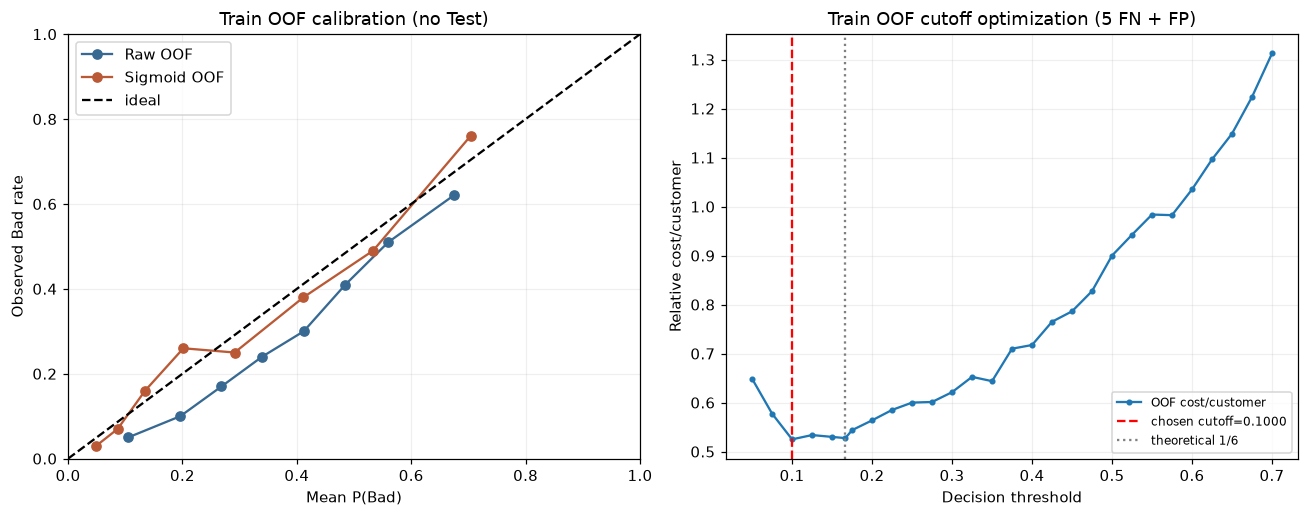

TRAIN OOF results are used to CHOOSE a cutoff. Do not report their minimum as unbiased performance; use outer-fold results.


In [98]:
# Stage 7 — Final cutoff is selected ONLY from full-TRAIN (800) strictly cross-fitted probabilities.
# Fold-specific model family, hyperparameters, preprocessing and sigmoid calibrator are fitted without the fold's labels.
final_oof_prob,final_oof_raw,final_oof_model_folds=training_only_oof(
    X_train,y_train,n_folds=FINAL_OOF_FOLDS,seed=RANDOM_STATE+9000)
FIXED_CUTOFF,threshold_results,ordered=cutoff_from_training_only_oof(y_train,final_oof_prob)
assert abs(float(ordered.loc[0,'threshold'])-FIXED_CUTOFF)<1e-12
final_oof_model_folds.to_csv(OUT/'final_cutoff_oof_fold_models.csv',index=False)
threshold_results.to_csv(OUT/'threshold_selection_nested_oof.csv',index=False)
calibration_compare=pd.DataFrame([
 {'Model':'Raw OOF nested-tuned','Brier':brier_score_loss(y_train,final_oof_raw),'LogLoss':log_loss(y_train,final_oof_raw),'ROC-AUC':roc_auc_score(y_train,final_oof_raw)},
 {'Model':'Sigmoid OOF nested-tuned','Brier':brier_score_loss(y_train,final_oof_prob),'LogLoss':log_loss(y_train,final_oof_prob),'ROC-AUC':roc_auc_score(y_train,final_oof_prob)}])
display(calibration_compare.round(4))
print('FINAL training-only chosen cutoff:',FIXED_CUTOFF, '| OOF cost:',int(ordered.loc[0,'relative_cost']),
      '| theoretical 1/6:',round(THEORETICAL_COST_CUTOFF,5))
print('If the raw OOF Brier is lower, sigmoid is still the PREDECLARED calibration strategy; document this limitation.')
display(ordered.head(12).round(4))
fig,axs=plt.subplots(1,2,figsize=(12,4.8))
for scores,label,color in [(final_oof_raw,'Raw OOF','#376992'),(final_oof_prob,'Sigmoid OOF','#ba5935')]:
    frac,mean_pred=calibration_curve(y_train,scores,n_bins=8,strategy='quantile')
    axs[0].plot(mean_pred,frac,'o-',label=label,color=color)
axs[0].plot([0,1],[0,1],'k--',label='ideal')
axs[0].set(title='Train OOF calibration (no Test)',xlabel='Mean P(Bad)',ylabel='Observed Bad rate',xlim=(0,1),ylim=(0,1));axs[0].legend()
axs[1].plot(threshold_results.threshold,threshold_results.cost_per_customer,'.-',label='OOF cost/customer')
axs[1].axvline(FIXED_CUTOFF,color='red',ls='--',label=f'chosen cutoff={FIXED_CUTOFF:.4f}')
axs[1].axvline(THEORETICAL_COST_CUTOFF,color='gray',ls=':',label='theoretical 1/6')
axs[1].set(title='Train OOF cutoff optimization (5 FN + FP)',xlabel='Decision threshold',ylabel='Relative cost/customer')
axs[1].legend(fontsize=8)
plt.tight_layout();plt.savefig(OUT/'07_threshold_nested_oof_cost_and_calibration.png',dpi=170);plt.show()
print('TRAIN OOF results are used to CHOOSE a cutoff. Do not report their minimum as unbiased performance; use outer-fold results.')

### 7.5 — Reading the nested-CV and threshold outputs

The preceding execution produces several distinct forms of evidence:

| Output | Meaning | Interpretation boundary |
|:--|:--|:--|
| **Outer-fold assessment** | Performance of the full model/calibration/threshold *selection procedure* on fold-held-out observations | Repeated folds overlap; variability is descriptive |
| **Training-only OOF threshold table** | Relative classification loss for each candidate cut-off | The minimum is used to **choose** the threshold, so its score is not an unbiased future-loss estimate |
| **Raw versus sigmoid OOF calibration** | Brier score, log loss, and calibration curves for OOF probabilities | Calibration is predeclared and should not be retrospectively selected using Test outcomes |
| **Subgroup audit** | Error rates by recorded demographic and proxy-sensitive categories | Small groups and historic coding limit fairness conclusions |

**Reading the threshold plot:** Compare the empirical loss curve with the selected cut-off and the theoretical reference line. Their agreement or disagreement is a **computed finding** to interpret after execution—not an assertion built into this Markdown.

**Scientific boundary:** Threshold optimization uses the available OOF labels. Nested outer-fold evaluation is the more appropriate evidence about the selection *procedure*, although it is still not a prospective external validation.


In [99]:
# TRAIN OOF group audit is descriptive and shares data with threshold selection; it is not an honest performance estimate.
train_oof_predict=(final_oof_prob>=FIXED_CUTOFF).astype(int)
def subgroup_table(Xpart,ypart,ppred,probs=None):
    x=Xpart.copy();x['Actual']=np.asarray(ypart);x['Pred']=np.asarray(ppred)
    x['Age_Group']=np.where(x['Age']<35,'Age < 35','Age >= 35')
    sexmap={'A91':'Male','A93':'Male','A94':'Male','A92':'Female','A95':'Female'}
    x['Sex_Derived_From_Combined_Code']=x['Personal_Status_Sex'].map(sexmap)
    rows=[]
    for col in ['Age_Group','Sex_Derived_From_Combined_Code','Foreign_Worker']:
        for g,t in x.groupby(col):
            cm=confusion_matrix(t.Actual,t.Pred,labels=[0,1]);tn,fp,fn,tp=cm.ravel()
            rows.append({'Group variable':col,'Group':g,'N':len(t),'Bad_n':int((t.Actual==1).sum()),
                         'FPR':fp/(fp+tn) if fp+tn else np.nan,'FNR':fn/(fn+tp) if fn+tp else np.nan,
                         'TPR':tp/(tp+fn) if tp+fn else np.nan,
                         'small_group_warning':len(t)<30 or min(int((t.Actual==0).sum()),int((t.Actual==1).sum()))<10})
    return pd.DataFrame(rows)
pretest_fairness=subgroup_table(X_train,y_train,train_oof_predict)
display(pretest_fairness.round(3));pretest_fairness.to_csv(OUT/'fairness_train_oof_diagnostic.csv',index=False)
print('TRAIN OOF group audit only; threshold selected from these same labels; not an independent performance/fairness claim.')
print('Original sex/status variable conflates attributes; small-group warnings matter.')


,Group variable,Group,N,Bad_n,FPR,FNR,TPR,small_group_warning
0,Age_Group,Age < 35,443,151,0.774,0.026,0.974,False
1,Age_Group,Age >= 35,357,89,0.593,0.034,0.966,False
2,Sex_Derived_From_Combined_Code,Female,249,89,0.800,0.022,0.978,False
3,Sex_Derived_From_Combined_Code,Male,551,151,0.642,0.033,0.967,False
4,Foreign_Worker,A201,769,237,0.701,0.030,0.970,False
5,Foreign_Worker,A202,31,3,0.429,0.000,1.000,True


TRAIN OOF group audit only; threshold selected from these same labels; not an independent performance/fairness claim.
Original sex/status variable conflates attributes; small-group warnings matter.


In [100]:
# Stage 7 — Freeze final fitting and cutoff BEFORE any test predictions.
# The final estimator uses the SAME tuning policy as Stage 6, trained and calibrated on ALL 800 Train cases.
final_probability_model=calibrated_fit_train_only(selected_estimator,X_train,y_train,seed=RANDOM_STATE+12000)
FINAL_FITTED_MODEL_ID=id(final_probability_model)
FINAL_TRAIN_PROB_SIGNATURE=np.round(final_probability_model.predict_proba(X_train.iloc[:20])[:,1],10)
MODEL_FREEZE={
    'selected_model':selected_name,'selected_hyperparameters':selected_search.best_params_,
    'raw_features':list(X_train.columns),'financial_features':['Credit_Amount_Per_Month','Long_Employment'],
    'train_size':int(len(X_train)),'test_size':int(len(X_test)),
    'preprocessor':'train-fold numeric median + nominal OneHot; deterministic engineered features; no scaling/capping',
    'model_selection':'Decision Tree/Random Forest GridSearchCV, mean AP (Bad=1), 3 stratified folds',
    'calibration':'predeclared sigmoid cross-fit (3 stratified folds, ensemble=False)',
    'outer_estimation':'Repeated stratified 5x2 CV; each outer split reselects model/cutoff within its training portion',
    'cutoff_selection':'5fold TRAIN-only OOF; full model family/hyperparameter selection nested within each OOF training fold',
    'cutoff_cost':'FP + 5*FN','cutoff':float(FIXED_CUTOFF),
    'cutoff_tie_rule':'closest to theoretical 1/6 if cost equal; then smaller cutoff',
    'outer_mean_cost_per_customer':float(nested_outer_results.cost_per_customer.mean()),
    'outer_sd_cutoff_descriptive':float(nested_outer_results.cutoff.std(ddof=1)),
    'seed':RANDOM_STATE,
    'test_disclosure':'Prior project iterations viewed this same holdout; historical descriptive audit only; never used for selection.',
    'note':'Final model fitted on all 800 Train and frozen here, before any Test prediction.'}
(OUT/'model_freeze.json').write_text(json.dumps(MODEL_FREEZE,ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps(MODEL_FREEZE,ensure_ascii=False,indent=2))
print('Final model is ALREADY fitted and frozen. Stage 8 must reuse this exact object, not refit it.')

{
  "selected_model": "Random Forest",
  "selected_hyperparameters": {
    "model__class_weight": null,
    "model__max_depth": null,
    "model__min_samples_leaf": 5
  },
  "raw_features": [
    "Checking_Account",
    "Duration",
    "Credit_History",
    "Purpose",
    "Credit_Amount",
    "Savings_Account",
    "Employment_Status",
    "Installment_Rate",
    "Personal_Status_Sex",
    "Other_Debtors",
    "Residence_Since",
    "Property",
    "Age",
    "Other_Installment_Plans",
    "Housing",
    "Existing_Credits",
    "Job",
    "Dependents",
    "Telephone",
    "Foreign_Worker"
  ],
  "financial_features": [
    "Credit_Amount_Per_Month",
    "Long_Employment"
  ],
  "train_size": 800,
  "test_size": 200,
  "preprocessor": "train-fold numeric median + nominal OneHot; deterministic engineered features; no scaling/capping",
  "model_selection": "Decision Tree/Random Forest GridSearchCV, mean AP (Bad=1), 3 stratified folds",
  "calibration": "predeclared sigmoid cross-fit (3 s

## Stage 8 — Historical holdout evaluation of the frozen decision rule

**Objective:** Report discrimination, probability quality, and decision consequences on the historical Test **after** all model-development choices have been frozen.

### Outputs and interpretation

| Report | What it answers |
|:--|:--|
| **Benchmark comparison** | How the Decision Tree, Random Forest, and selected calibrated model rank cases (ROC-AUC and AP) and estimate probabilities (Brier score) |
| **ROC and precision–recall curves** | How the ranking trade-offs vary over score thresholds |
| **Confusion matrix** | How many predictions fall into TN, FP, FN, and TP at the preselected threshold |
| **Relative benchmark loss** | The weighted total of false-positive and false-negative decisions |
| **Reliability curve** | Whether predicted probability groups align descriptively with observed Bad rates |
| **Subgroup diagnostics** | How measured errors vary across selected historical groups, with sample-size warnings |

**Distinguish these concepts:** ROC-AUC and AP describe ranking; Brier score describes probability accuracy; and a confusion matrix describes decisions at **one specific cut-off**. A higher Bad recall can come at the cost of more Good applicants being flagged.

**Frozen-policy rule:** The code verifies that the selected fitted estimator and its training-probability signature have not changed before evaluation. Baseline/challenger models are refitted on Train for reporting; the selected calibrated estimator itself is reused **without Test-based refitting or threshold adjustment**.

> **Evidence limitation:** Prior project iterations already inspected this historical holdout. It is therefore a descriptive historical audit, not new independent validation. Bootstrap ranges and subgroup tables do not remove that limitation. Consult the executed comparison, confusion matrix, and cost output for the current numbers.


### 8.1 — Evaluate the unchanged fitted model

The next cells validate the model-freeze checks, compute the model comparison, apply `FIXED_CUTOFF` to the selected calibrated probabilities, and save the resulting confusion matrix, relative cost, and ROC/PR curves.

**Review:** Verify the stored cut-off was chosen before Test access. The Test is not used for model refitting, recalibration, or cut-off selection. Report observed values from the code output rather than from narrative text.


,Model,ROC-AUC,PR-AUC (AP),Brier
0,Decision Tree baseline,0.7356,0.5273,0.1796
1,Random Forest challenger,0.8061,0.6801,0.1619
2,SELECTED Random Forest + Sigmoid calibration,0.8061,0.6801,0.1548


Chosen algorithm (all-Train CV + outer nested evaluation): Random Forest
Frozen NESTED cutoff: 0.1  | historical test TN,FP,FN,TP: (np.int64(38), np.int64(102), np.int64(2), np.int64(58))
Historical Test relative cost = 5*FN + FP = 112
              precision    recall  f1-score   support

    Good (0)       0.95      0.27      0.42       140
     Bad (1)       0.36      0.97      0.53        60

    accuracy                           0.48       200
   macro avg       0.66      0.62      0.47       200
weighted avg       0.77      0.48      0.45       200



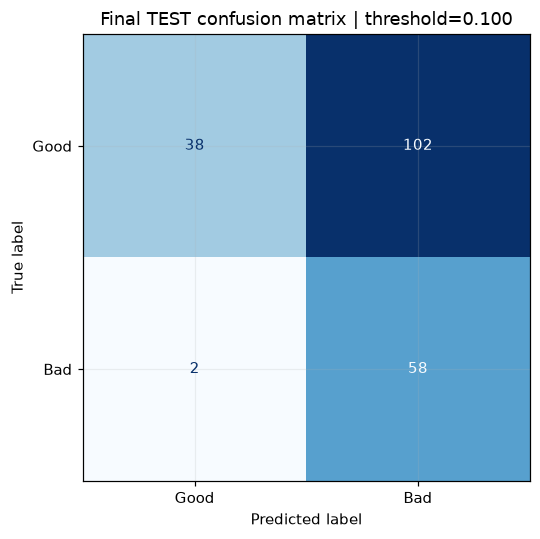

In [101]:
# Stage 8: historical TEST is evaluated after complete Train-only freeze; NEVER refit final_probability_model here.
final_dt=clone(dt_search.best_estimator_).fit(X_train,y_train)
final_rf=clone(rf_search.best_estimator_).fit(X_train,y_train)
assert id(final_probability_model)==FINAL_FITTED_MODEL_ID, 'Final fitted model was changed after freeze'
assert np.allclose(final_probability_model.predict_proba(X_train.iloc[:20])[:,1],FINAL_TRAIN_PROB_SIGNATURE), 'Final fitted probabilities changed after freeze'
# final test probability only; the original chosen-model ROC/PR comparison is unchanged by threshold
p_dt=final_dt.predict_proba(X_test)[:,1]
p_rf=final_rf.predict_proba(X_test)[:,1]
p_selected=final_probability_model.predict_proba(X_test)[:,1]
test_comparison=pd.DataFrame([
 {'Model':'Decision Tree baseline','ROC-AUC':roc_auc_score(y_test,p_dt),'PR-AUC (AP)':average_precision_score(y_test,p_dt), 'Brier':brier_score_loss(y_test,p_dt)},
 {'Model':'Random Forest challenger','ROC-AUC':roc_auc_score(y_test,p_rf),'PR-AUC (AP)':average_precision_score(y_test,p_rf), 'Brier':brier_score_loss(y_test,p_rf)},
 {'Model':f'SELECTED {selected_name} + Sigmoid calibration','ROC-AUC':roc_auc_score(y_test,p_selected),'PR-AUC (AP)':average_precision_score(y_test,p_selected), 'Brier':brier_score_loss(y_test,p_selected)}])
display(test_comparison.round(4));test_comparison.to_csv(OUT/'final_test_model_comparison.csv',index=False)
final_test_pred=(p_selected>=FIXED_CUTOFF).astype(int)
cm=confusion_matrix(y_test,final_test_pred,labels=[0,1]);tn,fp,fn,tp=cm.ravel()
relative_cost=5*fn+fp
print('Chosen algorithm (all-Train CV + outer nested evaluation):',selected_name)
print('Frozen NESTED cutoff:',FIXED_CUTOFF,' | historical test TN,FP,FN,TP:',(tn,fp,fn,tp))
print('Historical Test relative cost = 5*FN + FP =',relative_cost)
print(classification_report(y_test,final_test_pred,target_names=['Good (0)','Bad (1)'],zero_division=0))
fig,ax=plt.subplots(figsize=(6,5));ConfusionMatrixDisplay(cm,display_labels=['Good','Bad']).plot(ax=ax,cmap='Blues',colorbar=False);ax.set_title(f'Final TEST confusion matrix | threshold={FIXED_CUTOFF:.3f}');plt.tight_layout();plt.savefig(OUT/'08_confusion_matrix_test.png',dpi=170);plt.show()


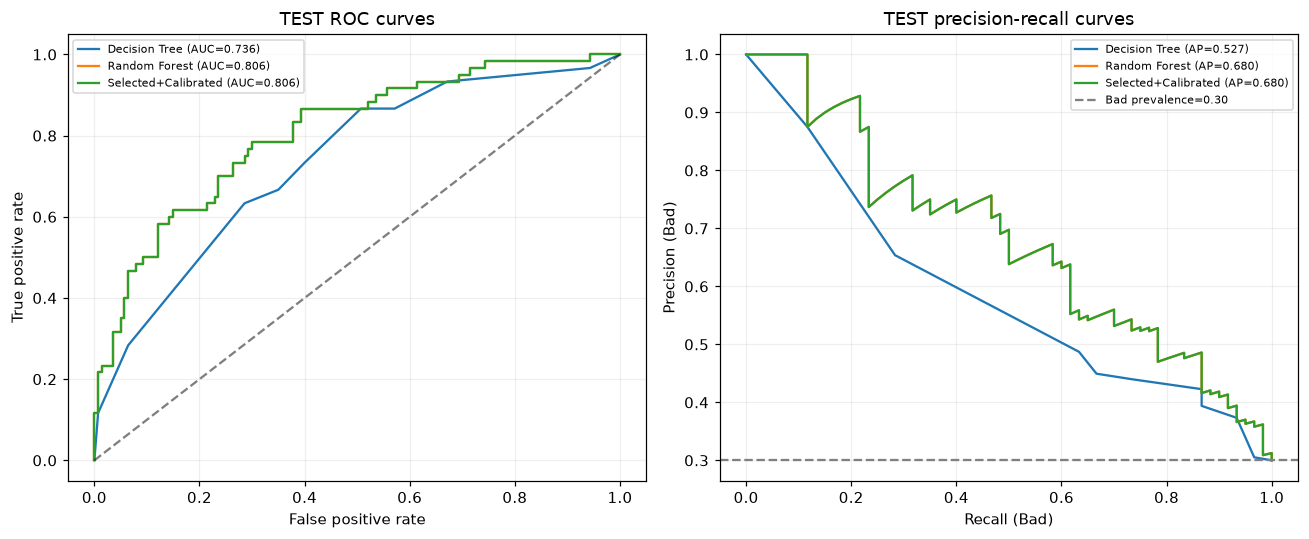

Exploratory 95% stratified bootstrap interval on HISTORICALLY REUSED Test (not fresh evidence):
ROC-AUC: [0.744 0.874]  | AP: [0.594 0.783]


In [102]:
fig,axs=plt.subplots(1,2,figsize=(12,5))
for prob,label in [(p_dt,'Decision Tree'),(p_rf,'Random Forest'),(p_selected,'Selected+Calibrated')]:
    fpr,tpr,_=roc_curve(y_test,prob)
    prec,rec,_=precision_recall_curve(y_test,prob)
    axs[0].plot(fpr,tpr,label=f'{label} (AUC={roc_auc_score(y_test,prob):.3f})')
    axs[1].plot(rec,prec,label=f'{label} (AP={average_precision_score(y_test,prob):.3f})')
axs[0].plot([0,1],[0,1],'k--',alpha=.5)
axs[1].axhline(y_test.mean(),color='gray',linestyle='--',label=f'Bad prevalence={y_test.mean():.2f}')
axs[0].set(title='TEST ROC curves',xlabel='False positive rate',ylabel='True positive rate');axs[0].legend(fontsize=7)
axs[1].set(title='TEST precision-recall curves',xlabel='Recall (Bad)',ylabel='Precision (Bad)');axs[1].legend(fontsize=7)
plt.tight_layout();plt.savefig(OUT/'09_roc_pr_test.png',dpi=170);plt.show()
# Confidence intervals: stratified bootstrap of paired test predictions (descriptive only, not model selection)
boot=[]
ids0=np.where(np.asarray(y_test)==0)[0];ids1=np.where(np.asarray(y_test)==1)[0]
for _ in range(500):
 ids=np.r_[rng.choice(ids0,size=len(ids0),replace=True),rng.choice(ids1,size=len(ids1),replace=True)]
 ya=np.asarray(y_test)[ids];pa=p_selected[ids]
 boot.append([roc_auc_score(ya,pa),average_precision_score(ya,pa)])
boot=np.asarray(boot)
print('Exploratory 95% stratified bootstrap interval on HISTORICALLY REUSED Test (not fresh evidence):')
print('ROC-AUC:',np.round(np.quantile(boot[:,0],[.025,.975]),3),' | AP:',np.round(np.quantile(boot[:,1],[.025,.975]),3))


,Group variable,Group,N,Bad_n,FPR,FNR,TPR,small_group_warning
0,Age_Group,Age < 35,105,41,0.781,0.049,0.951,False
1,Age_Group,Age >= 35,95,19,0.684,0.000,1.000,False
2,Sex_Derived_From_Combined_Code,Female,61,20,0.780,0.050,0.950,False
3,Sex_Derived_From_Combined_Code,Male,139,40,0.707,0.025,0.975,False
4,Foreign_Worker,A201,194,59,0.726,0.034,0.966,False
5,Foreign_Worker,A202,6,1,0.800,0.000,1.000,True


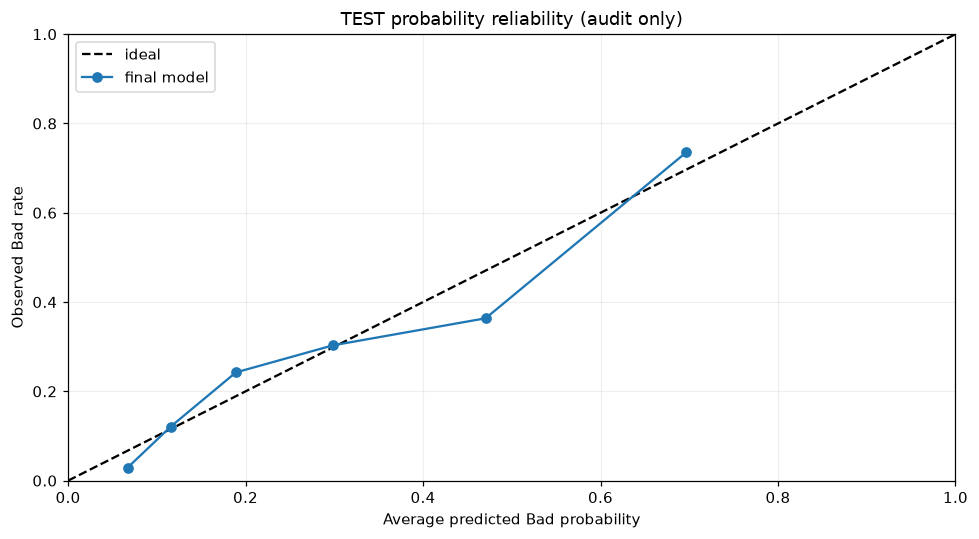

Historical Test audit/report ONLY: no model/threshold adjustment; historical access means not fully fresh.


In [103]:
# Final test subgroup audit; purely descriptive, with explicit small-group warnings.
test_fairness=subgroup_table(X_test,y_test,final_test_pred)
display(test_fairness.round(3));test_fairness.to_csv(OUT/'fairness_test_audit.csv',index=False)
# Probability diagnostic on held-out test, NOT re-fitting calibration.
frac,avg=calibration_curve(y_test,p_selected,n_bins=6,strategy='quantile')
fig,ax=plt.subplots();ax.plot([0,1],[0,1],'k--',label='ideal');ax.plot(avg,frac,'o-',label='final model')
ax.set(title='TEST probability reliability (audit only)',xlabel='Average predicted Bad probability',ylabel='Observed Bad rate',xlim=(0,1),ylim=(0,1));ax.legend();plt.tight_layout();plt.savefig(OUT/'10_test_reliability.png',dpi=170);plt.show()
print('Historical Test audit/report ONLY: no model/threshold adjustment; historical access means not fully fresh.')


### 8.2 — Business implications and evidence limitations

The cost-sensitive rule reflects a trade-off: identifying more genuinely Bad cases may also flag more Good applicants. Interpret the executed confusion matrix using **false-negative count, false-positive count, Bad recall, Good-case false-positive rate, and relative benchmark loss** together.

The benchmark loss is a **relative cost index**, not observed currency loss. Ranking quality (ROC-AUC/AP), calibration quality (Brier and reliability), and policy consequences (confusion matrix at the fixed cut-off) answer different questions.

**Additional diagnostics:** The code reports exploratory bootstrap ranges and subgroup error tables based on age bands, combined status/sex categories, and foreign-worker coding. Some groups may be small; these checks do **not** certify fairness, legal compliance, or suitability for automated lending.

**Before deployment:** Require newly collected, time-relevant validation data; review actual operating costs and decision policies; examine group impacts and proxy variables; and retain appropriate human oversight.


## Stage 9 — Explainable AI: global and local SHAP

**Objective:** Explain how the fitted tree-based model uses its transformed inputs while keeping those explanations distinct from the final calibrated decision probability.

### Explanation outputs

| Visualization | Question addressed | Reading guidance |
|:--|:--|:--|
| **Global SHAP beeswarm** | Which transformed inputs affect predictions, in which direction, and with what variation across sampled training cases? | Position shows contribution; color indicates feature value where applicable |
| **Global SHAP bar** | Which transformed inputs have the largest **mean absolute** contributions? | Bar length measures magnitude, **not direction** |
| **Low-score waterfall** | How do feature contributions build the raw-model score for a selected lower-risk case? | Read the base value and signed contributions |
| **High-score waterfall** | How do feature contributions build the raw-model score for a selected higher-risk case? | Interpret this individual case, not all applicants |

**Critical scale distinction:** TreeSHAP is computed for the underlying **uncalibrated tree-based estimator** and reconstructs its raw Bad-class probability. The operational threshold is applied to the **sigmoid-calibrated probability**. Raw-tree SHAP contributions must **not** be summed and presented as the calibrated final probability.

**Fairness and causality:** SHAP explains behavior of a fitted predictive model, not actual causes of default or lawful grounds for a real credit decision. The names and signed contributions of leading features depend on the current run; read them from the generated plots and tables.


### 9.1 — Extract the fitted tree and produce SHAP plots

The next cells retrieve the underlying fitted tree-based Pipeline from the calibration wrapper, reproduce the same feature transformations used in training, and calculate global/local TreeSHAP explanations.

**Verification:** Confirm that transformed feature names align with the SHAP matrix and distinguish the **raw tree probability** from the **calibrated score** printed for each example. The generated figures and attribution tables contain the run-specific results.


In [104]:
print('SHAP version:',shap.__version__)
# ensemble=False ensures the final calibration wrapper has one fitted base pipeline.
base_final_pipeline=final_probability_model.calibrated_classifiers_[0].estimator
base_domain=base_final_pipeline.named_steps['domain']
base_preprocess=base_final_pipeline.named_steps['preprocess']
base_tree=base_final_pipeline.named_steps['model']
encoded_feature_names=list(base_preprocess.get_feature_names_out())
X_global=X_train.sample(n=min(110,len(X_train)),random_state=RANDOM_STATE+7)
idx_low=np.flatnonzero(final_test_pred==0)
idx_high=np.flatnonzero(final_test_pred==1)
if len(idx_low)==0 or len(idx_high)==0:
    low_i=int(np.argmin(p_selected));high_i=int(np.argmax(p_selected))
else:
    low_i=int(idx_low[np.argmin(p_selected[idx_low])]);high_i=int(idx_high[np.argmax(p_selected[idx_high])])
X_local=X_test.iloc[[low_i,high_i]].copy()
xt_global=np.asarray(base_preprocess.transform(base_domain.transform(X_global)),dtype=float)
xt_local=np.asarray(base_preprocess.transform(base_domain.transform(X_local)),dtype=float)
assert xt_global.shape[1]==len(encoded_feature_names)
base_shap=shap.TreeExplainer(base_tree)

def bad_class_shap(x):
    values=base_shap.shap_values(x)
    if isinstance(values,list):
        arr=np.asarray(values[1])
    else:
        arr=np.asarray(values)
        if arr.ndim==3:arr=arr[:,:,1]
    expected=np.asarray(base_shap.expected_value).ravel()
    base=float(expected[1] if len(expected)>1 else expected[0])
    assert arr.shape==x.shape,(arr.shape,x.shape)
    return shap.Explanation(values=arr,base_values=np.full(x.shape[0],base),
                            data=x,feature_names=encoded_feature_names)

GLOBAL_EXPLANATIONS=bad_class_shap(xt_global)
LOCAL_EXPLANATIONS=bad_class_shap(xt_local)
print('SHAP feature count:',len(encoded_feature_names),'global cases:',len(X_global),'local:',len(X_local))
print('SHAP explains base uncalibrated tree P(Bad=1); NOT the final calibrated P(Bad=1).')
print('Final calibrated local P(Bad)=',p_selected[[low_i,high_i]])
print('Underlying raw local P(Bad)=',base_final_pipeline.predict_proba(X_local)[:,1])


SHAP version: 0.51.0
SHAP feature count: 63 global cases: 110 local: 2
SHAP explains base uncalibrated tree P(Bad=1); NOT the final calibrated P(Bad=1).
Final calibrated local P(Bad)= [0.04091489 0.87825079]
Underlying raw local P(Bad)= [0.03028411 0.69899624]


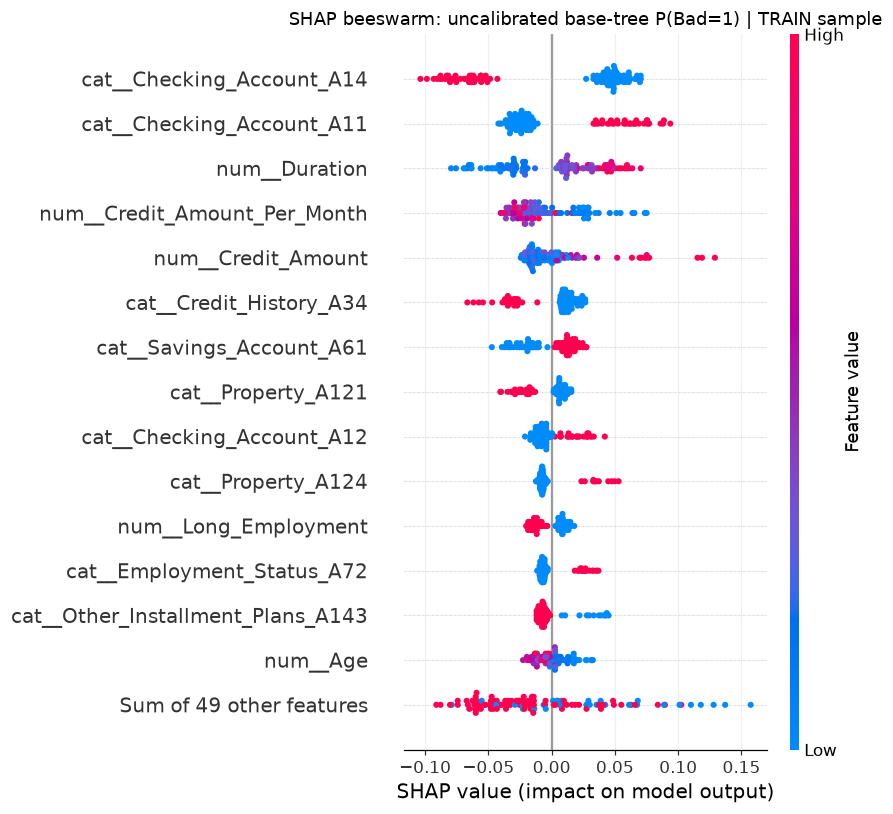

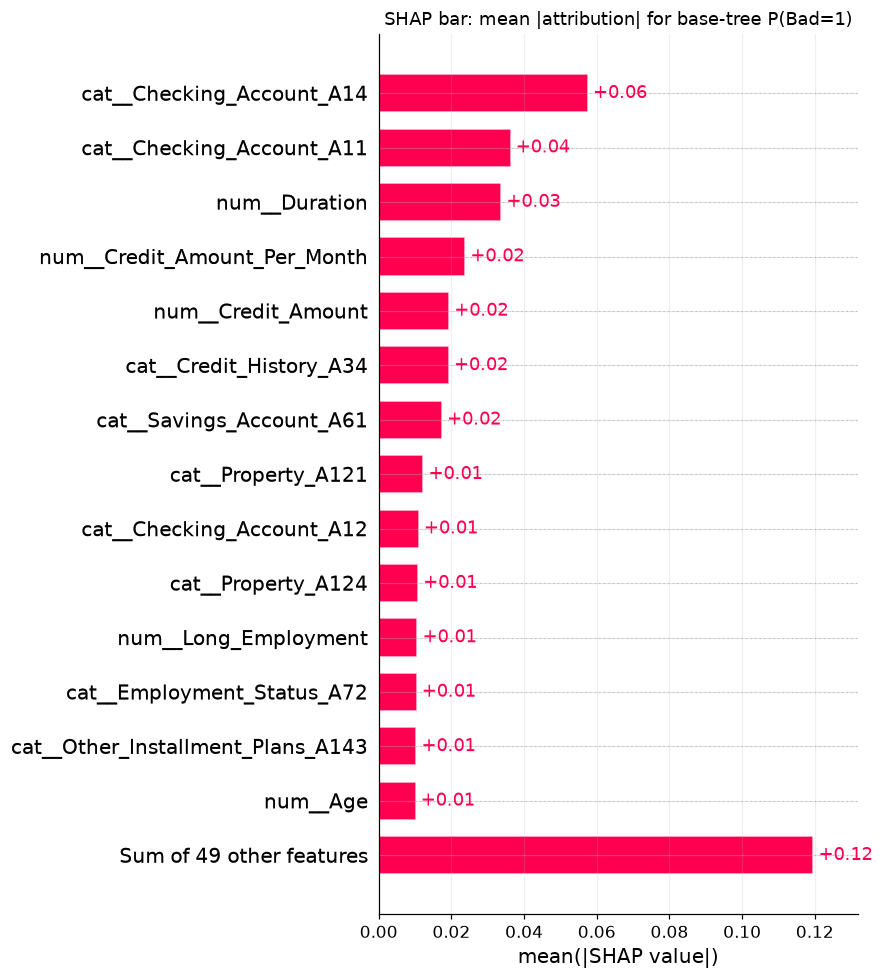

,Feature,Mean_abs_SHAP
12,cat__Checking_Account_A14,0.057565
9,cat__Checking_Account_A11,0.036298
0,num__Duration,0.033742
7,num__Credit_Amount_Per_Month,0.023816
1,num__Credit_Amount,0.019392
17,cat__Credit_History_A34,0.019296
28,cat__Savings_Account_A61,0.017421
45,cat__Property_A121,0.012306
10,cat__Checking_Account_A12,0.011036
48,cat__Property_A124,0.010842


In [105]:
# Required global SHAP beeswarm and bar plots
plt.figure()
shap.plots.beeswarm(GLOBAL_EXPLANATIONS,max_display=15,show=False)
plt.title('SHAP beeswarm: uncalibrated base-tree P(Bad=1) | TRAIN sample')
plt.tight_layout();plt.savefig(OUT/'11_shap_beeswarm.png',dpi=165,bbox_inches='tight');plt.show()
plt.figure()
shap.plots.bar(GLOBAL_EXPLANATIONS,max_display=15,show=False)
plt.title('SHAP bar: mean |attribution| for base-tree P(Bad=1)')
plt.tight_layout();plt.savefig(OUT/'12_shap_bar.png',dpi=165,bbox_inches='tight');plt.show()
shap_rank=pd.DataFrame({'Feature':encoded_feature_names,'Mean_abs_SHAP':np.mean(np.abs(GLOBAL_EXPLANATIONS.values),axis=0)}).sort_values('Mean_abs_SHAP',ascending=False)
display(shap_rank.head(12));shap_rank.to_csv(OUT/'shap_global_attributions.csv',index=False)


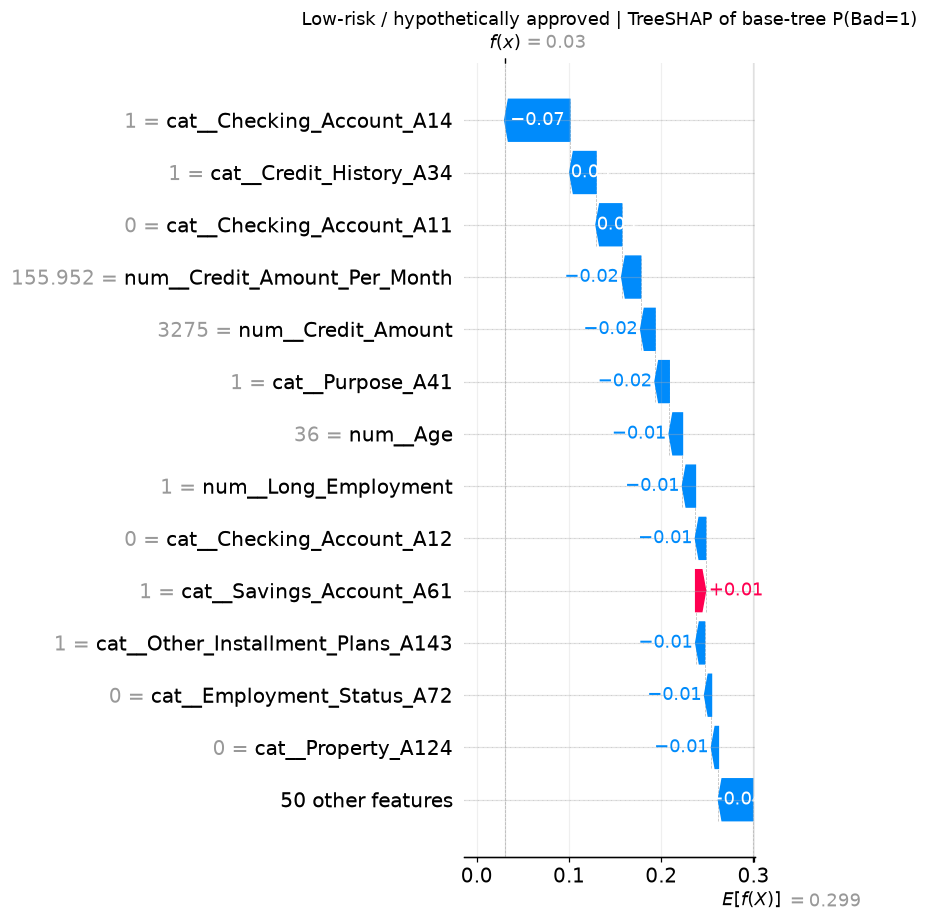

CASE Low-risk / hypothetically approved p(Bad)= 0.04091488746620568 sum SHAP + base (raw tree) ≈ 0.03028410849241764


,SHAP contribution to P(Bad)
cat__Checking_Account_A14,-0.070455
cat__Credit_History_A34,-0.028453
cat__Checking_Account_A11,-0.027847
num__Credit_Amount_Per_Month,-0.020557
num__Credit_Amount,-0.015595
cat__Purpose_A41,-0.015350
num__Age,-0.014353
num__Long_Employment,-0.014049


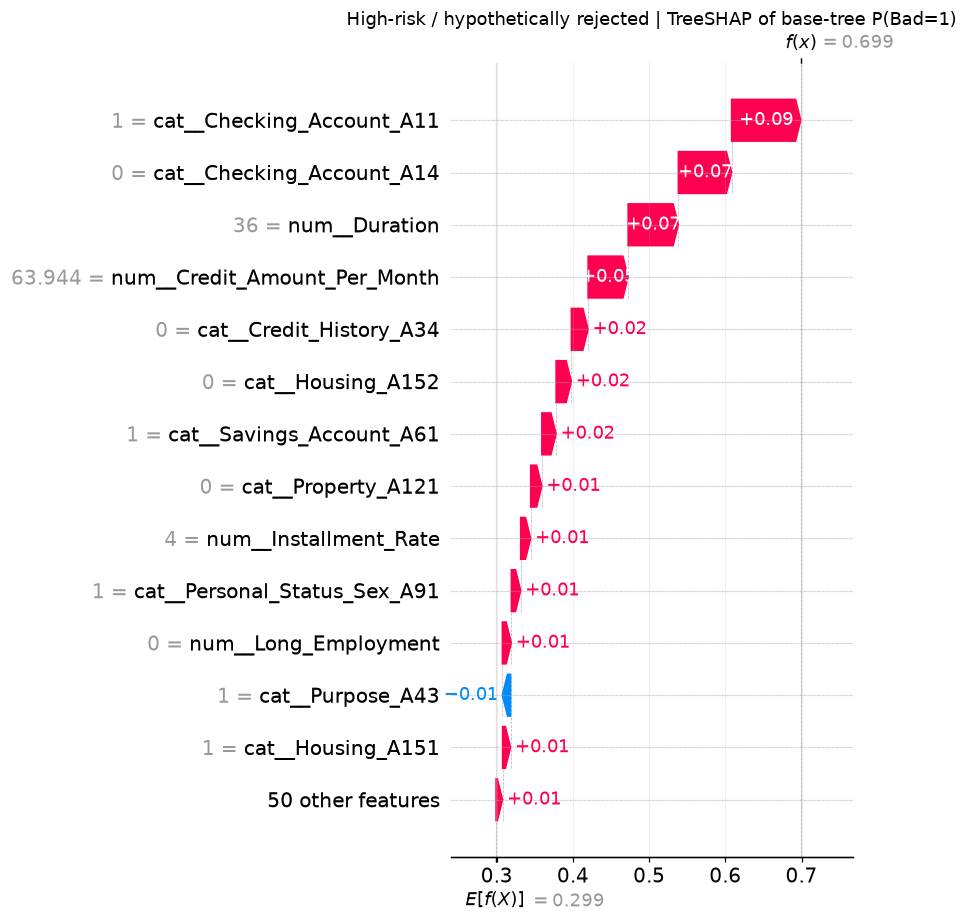

CASE High-risk / hypothetically rejected p(Bad)= 0.8782507859512849 sum SHAP + base (raw tree) ≈ 0.6989962359528419


,SHAP contribution to P(Bad)
cat__Checking_Account_A11,0.090726
cat__Checking_Account_A14,0.069920
num__Duration,0.065900
num__Credit_Amount_Per_Month,0.052550
cat__Credit_History_A34,0.021979
cat__Housing_A152,0.020024
cat__Savings_Account_A61,0.018699
cat__Property_A121,0.014662


In [106]:
for j,case_title in [(0,'Low-risk / hypothetically approved'),(1,'High-risk / hypothetically rejected')]:
    explanation=LOCAL_EXPLANATIONS[j]
    shap.plots.waterfall(explanation,max_display=14,show=False)
    plt.title(case_title+' | TreeSHAP of base-tree P(Bad=1)')
    plt.tight_layout();plt.savefig(OUT/f'13_shap_waterfall_{j+1}.png',dpi=165,bbox_inches='tight');plt.show()
    scores=pd.Series(explanation.values,index=encoded_feature_names)
    print('CASE',case_title,'p(Bad)=',float(p_selected[[low_i,high_i]][j]),'sum SHAP + base (raw tree) ≈',float(explanation.base_values+scores.sum()))
    display(scores.reindex(scores.abs().sort_values(ascending=False).head(8).index).to_frame('SHAP contribution to P(Bad)'))


### 9.2 — Optional LIME-style local comparison

The next cells fit a **distance-weighted local linear surrogate** around a selected high-risk case, using perturbed observations and the final calibrated model's probability outputs. They also attempt an official `LimeTabularExplainer` visualization where the package is available.

**How to interpret the output:**

- **Weighted local $R^2$** describes how closely the surrogate approximates the calibrated model *in the sampled neighborhood*; read the computed value from the output.
- **Local coefficients** reflect changes in the surrogate's interpretable representation and are not exact feature contributions for the original model.
- **SHAP attributions** in this notebook refer to the underlying raw tree probability; LIME-like coefficients approximate the calibrated model. Their scales and definitions differ, so compare qualitative patterns cautiously rather than equating numerical values.

The surrogate is an optional interpretability aid. Local fidelity and feature rankings must be assessed from each execution, not assumed in advance.


In [107]:
local_case=X_local.iloc[1].copy()
Z=[]
for _ in range(550):
 row=local_case.copy()
 for col in X_train.columns:
    if rng.random()<.35:
        if col in NUMERIC:
            row[col]=float(X_train[col].iloc[rng.integers(len(X_train))])
        else:row[col]=X_train[col].iloc[rng.integers(len(X_train))]
 Z.append(row)
perturbed=pd.DataFrame(Z,columns=X_train.columns)
model_prob=final_probability_model.predict_proba(perturbed)[:,1]
# interpretable binary proximity indicators: same category / numeric within fixed TRAIN IQR-scaled band
interpretable=np.empty((len(perturbed),len(X_train.columns)))
for k,c in enumerate(X_train.columns):
 if c in CATEGORICAL:interpretable[:,k]=(perturbed[c].to_numpy()==local_case[c]).astype(float)
 else:
    scale=max(float(X_train[c].std()),1e-8)
    interpretable[:,k]=(np.abs(perturbed[c].astype(float)-float(local_case[c]))/scale <.4).astype(float)
numdist=np.zeros(len(perturbed))
for c in NUMERIC:
 scale=max(float(X_train[c].std()),1e-8)
 numdist+=((perturbed[c].astype(float)-float(local_case[c]))/scale)**2
catdist=sum((perturbed[c]!=local_case[c]).astype(float).to_numpy() for c in CATEGORICAL)
distance=np.sqrt(numdist/len(NUMERIC)+catdist/len(CATEGORICAL))
weights=np.exp(-(distance**2)/(0.85**2))
local_linear=Ridge(alpha=.3).fit(interpretable,model_prob,sample_weight=weights)
local_linear_scores=pd.Series(local_linear.coef_,index=X_train.columns).sort_values(key=np.abs,ascending=False)
print('Local surrogate on high-risk case | weighted R^2:',round(local_linear.score(interpretable,model_prob,sample_weight=weights),3))
print('Important: surrogate coefficients are LOCAL approximate and are not exact SHAP values.')
display(local_linear_scores.head(10).to_frame('LIME-like local coefficient'))
# Aggregate encoded TreeSHAP indicators back to each original category feature for comparison.
def original_key(encoded):
 if encoded.startswith('num__'):return encoded[len('num__'):]
 if encoded.startswith('cat__'):
    for original in CATEGORICAL:
        if encoded.startswith(f'cat__{original}_'):return original
 return encoded
local_shap_agg=pd.Series(LOCAL_EXPLANATIONS[1].values,index=encoded_feature_names)
local_shap_agg=local_shap_agg.groupby([original_key(f) for f in encoded_feature_names]).sum()
comparison_lime=pd.DataFrame({'SHAP contribution of base tree (sum of encoded components)':local_shap_agg,
                              'LIME-like local coefficient':local_linear_scores}).fillna(0)
display(comparison_lime.loc[comparison_lime['SHAP contribution of base tree (sum of encoded components)'].abs().sort_values(ascending=False).head(10).index])
comparison_lime.to_csv(OUT/'lime_like_vs_shap.csv')


Local surrogate on high-risk case | weighted R^2: 0.688
Important: surrogate coefficients are LOCAL approximate and are not exact SHAP values.


,LIME-like local coefficient
Checking_Account,0.407137
Duration,0.189513
Savings_Account,0.081933
Credit_History,0.078632
Other_Installment_Plans,-0.070751
Housing,0.051473
Property,0.046951
Employment_Status,0.045188
Installment_Rate,0.042611
Residence_Since,0.030608


,SHAP contribution of base tree (sum of encoded components),LIME-like local coefficient
Checking_Account,0.159667,0.407137
Duration,0.065900,0.189513
Credit_Amount_Per_Month,0.052550,0.000000
Housing,0.031536,0.051473
Savings_Account,0.025481,0.081933
Credit_History,0.023212,0.078632
Personal_Status_Sex,0.013598,0.012468
Installment_Rate,0.013095,0.042611
Purpose,-0.012785,-0.013167
Property,0.012188,0.046951


,LIME feature condition,Local contribution
0,Checking_Account=0,0.207124
1,Duration > 24.00,0.132627
2,Other_Installment_Plans=2,-0.075543
3,Savings_Account=0,0.068812
4,Housing=0,0.055048
5,Foreign_Worker=0,0.036505
6,Purpose=4,-0.033584
7,Credit_History=2,0.030969
8,3.00 < Installment_Rate <= 4.00,0.030103
9,Personal_Status_Sex=0,0.026407


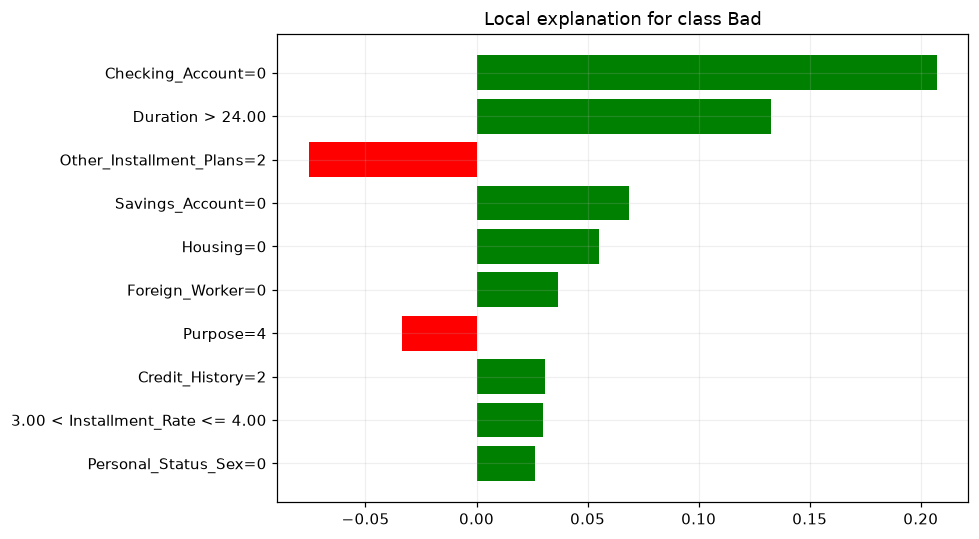

Official LIME successfully executed.


In [108]:
try:
    # encode raw data for official LimeTabularExplainer, define a decoding model wrapper
    ord_enc=OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1)
    train_ordinal=X_train.copy();test_ordinal=X_local.copy()
    train_ordinal[CATEGORICAL]=ord_enc.fit_transform(X_train[CATEGORICAL])
    test_ordinal[CATEGORICAL]=ord_enc.transform(X_local[CATEGORICAL])
    def lime_predict(encoded):
        fr=pd.DataFrame(encoded,columns=X_train.columns)
        for k,c in enumerate(CATEGORICAL):
            vec=np.rint(fr[c].to_numpy()).astype(int)
            vec=np.clip(vec,0,len(ord_enc.categories_[k])-1)
            fr[c]=np.asarray(ord_enc.categories_[k])[vec]
        for c in NUMERIC:fr[c]=pd.to_numeric(fr[c])
        return final_probability_model.predict_proba(fr)
    expl=lime.lime_tabular.LimeTabularExplainer(train_ordinal.to_numpy().astype(float),feature_names=list(X_train.columns),
               categorical_features=[X_train.columns.get_loc(c) for c in CATEGORICAL],
               class_names=['Good','Bad'],mode='classification',random_state=RANDOM_STATE)
    lime_result=expl.explain_instance(test_ordinal.iloc[1].to_numpy().astype(float),lime_predict,num_features=10,labels=[1])
    display(pd.DataFrame(lime_result.as_list(label=1),columns=['LIME feature condition','Local contribution']))
    fig=lime_result.as_pyplot_figure(label=1);plt.tight_layout();plt.savefig(OUT/'14_official_lime_optional.png',dpi=160);plt.show()
    print('Official LIME successfully executed.')
except ImportError:
    print('Official LIME package is not installed. The fully executed local-surrogate analogue above remains available, and the official LIME cell will run after installing `lime`.')


## Stage 10 — Predictive association versus causal effect

**Central principle:** A feature's correlation with the label, predictive usefulness, or SHAP contribution does **not** establish that intervening on that feature would change the probability of default.

- **Possible confounding:** Income, financial stability, historical lender practices, applicant selection, and macroeconomic conditions may influence both recorded predictors and repayment outcomes.
- **Prediction versus policy:** Credit history and account status may act as historical risk indicators. Loan amount and term may be negotiable, but their causal effects are not identified by this model.
- **Fairness boundary:** Age, combined personal-status/sex coding, and foreign-worker indicators require particular care; associations with them are not intervention recommendations or an adequate legal basis for decisions.

The next section answers the assignment's causal-reasoning questions without asserting results that depend on a specific fitted model.


### 10.1 — Responses to the causal-reasoning questions

**Q1. Which influential predictors can be regarded as causes, and which are correlated signals?**

The notebook's observational data and predictive analyses do **not establish a causal effect for any predictor**. Features such as `Checking_Account`, `Credit_History`, and `Savings_Account` may function as observed historical **risk indicators**. `Duration` and `Credit_Amount` are potentially adjustable contract terms, but it would require additional causal evidence to conclude that changing them changes default outcomes. SHAP describes a model's contributions to a prediction—not the effect of an intervention.

**Q2. What should risk management act on, and why can correlation-only rules be harmful?**

Prioritize lawful, testable actions such as verifying credit-record accuracy, assessing affordability with appropriate evidence, offering transparent contract choices, and obtaining qualified human review. Evaluate proposed interventions using prospective or causally informative evidence. Acting solely on correlations may fail to change actual repayment risk, encourage proxy discrimination, or unfairly restrict credit for otherwise eligible applicants.

**Limit of the study:** No intervention is experimentally evaluated here, and no feature is established as a proven causal lever.


## Stage 11 — Optional responsible-language communication example

**Objective:** Demonstrate how a predictive result could be explained in plain, respectful language without presenting a prototype output as a bank decision or treating SHAP values as causal evidence.

### Reusable prompt structure

> You are a responsible credit-risk explainer. Use the **calibrated Bad-class probability**, the **preselected decision threshold**, and the **case-specific model-attribution summary supplied by the executable cell**. Explain what the model estimated and which inputs influenced its score, using clear and respectful language. Do not invent personal facts, legal reasons, or numerical values. Do not describe SHAP contributions as causes of default. Suggest only general, non-guaranteed actions such as checking credit-record accuracy and reviewing affordable repayment options. State explicitly that the output is an educational prototype estimate and **not** an official lending decision.

### Required communication safeguards

- Insert probabilities, cut-offs, and attribution values **from the current execution**, not from fixed Markdown examples.
- Distinguish **calibrated decision probability** from **raw-tree SHAP contributions**.
- Avoid promises of approval, unsupported explanations, or claims about a person's character.
- Make clear that official credit decisions require independent evidence and suitable human/legal review.

**Example wording:** “This prototype assigned the application an elevated model-estimated risk score. Recorded account and loan attributes contributed to that statistical estimate, but they do not prove future nonpayment. The applicant can review the accuracy of the underlying information and discuss repayment options with an authorized adviser. This is not a formal credit decision.”

**Provenance:** The following code writes a prompt and a **manually authored** example. It does not claim that a live LLM generated the displayed example.


### 11.1 — Generate communication artifacts

The next cell assembles the optional prompt from the **current case-specific score, selected threshold, and stored SHAP values**, then saves `llm_prompt.txt` and `llm_manual_example.txt`.

The prompt and manually written example are produced by the existing executable code. The example is **not** a live LLM response. Inspect the generated text after each run; the Markdown intentionally contains no fixed case-specific metrics.


In [109]:
# Real SHAP values of our model's hypothetical declined test case are inserted into the prompt.
rejected_pos=1
local_contributions=pd.Series(LOCAL_EXPLANATIONS[rejected_pos].values,index=encoded_feature_names)
top_drivers=local_contributions.reindex(local_contributions.abs().nlargest(6).index)
PROMPT=f"""نقش شما: توضیح‌گر مسئول و محترمانه یک تصمیم اعتباری فرضی.
از خودتان هیچ دلیل یا عدد جدید نسازید. اثر SHAP را فقط سهم ویژگی در پیش‌بینی مدل بدانید، نه علت واقعی نکول.
از اطلاعات هویتی نپرسید و تضمین قبول‌شدن درخواست آینده ندهید.
برچسب مثبت: Bad Credit؛ احتمال برآوردشده همین داده آموزشی و مدل، نه PD بانکی با افق معلوم.
آستانه ثابت تصمیم: {FIXED_CUTOFF:.3f}؛ پیش‌بینی Bad این پرونده: {p_selected[high_i]:.3f}.
مشارکت SHAP در مدل درختی پایه (مقیاس احتمال خام Bad؛ این عددها اجزای احتمال نهایی کالیبره‌شده نیستند):
{top_drivers.round(4).to_string()}
در زبان ساده و محترمانه توضیح دهید این عوامل چگونه در پیش‌بینی مدل نقش داشته‌اند؛ سپس پیشنهادهای عمومی، عملی و غیرقطعی برای بررسی سوابق اعتباری، توان بازپرداخت و شرایط وام ارائه دهید.
این تصمیم فرضی مدل است نه تصمیم واقعی بانک. دلایل رسمی نیازمند بررسی مستقل و انسانی‌اند.
"""
print('=== Optional LLM PROMPT ===\n'+PROMPT)
(OUT/'llm_prompt.txt').write_text(PROMPT,encoding='utf-8')
manual_example=(
'نمونه پاسخ دستی ـ این متن توسط یک سرویس LLM تولید نشده است:\n'
'«در ارزیابی آزمایشی این درخواست، برخی اطلاعات مربوط به شرایط وام و سابقه اعتباری در امتیاز ریسک پیش‌بینی‌شده نقش داشته‌اند. '
'این نتیجه یک برآورد آماری است و دلیل قطعی بدحسابی آینده را مشخص نمی‌کند. '
'پیشنهاد می‌شود پیش از درخواست بعدی، اطلاعات سابقه اعتباری را بررسی کنید، درباره مبلغ و مدت بازپرداخت با کارشناس مجاز مشورت کنید '
'و مطمئن شوید شرایط بازپرداخت با توان مالی واقعی شما سازگار است. انجام این اقدامات تضمینی برای تأیید آینده نیست. '
'هر تصمیم رسمی باید با بررسی انسانی و مقررات مربوطه ارزیابی شود.»')
print('\n=== MANUALLY WRITTEN EXAMPLE ===\n',manual_example)
(OUT/'llm_manual_example.txt').write_text(manual_example,encoding='utf-8')


=== Optional LLM PROMPT ===
نقش شما: توضیح‌گر مسئول و محترمانه یک تصمیم اعتباری فرضی.
از خودتان هیچ دلیل یا عدد جدید نسازید. اثر SHAP را فقط سهم ویژگی در پیش‌بینی مدل بدانید، نه علت واقعی نکول.
از اطلاعات هویتی نپرسید و تضمین قبول‌شدن درخواست آینده ندهید.
برچسب مثبت: Bad Credit؛ احتمال برآوردشده همین داده آموزشی و مدل، نه PD بانکی با افق معلوم.
آستانه ثابت تصمیم: 0.100؛ پیش‌بینی Bad این پرونده: 0.878.
مشارکت SHAP در مدل درختی پایه (مقیاس احتمال خام Bad؛ این عددها اجزای احتمال نهایی کالیبره‌شده نیستند):
cat__Checking_Account_A11       0.0907
cat__Checking_Account_A14       0.0699
num__Duration                   0.0659
num__Credit_Amount_Per_Month    0.0525
cat__Credit_History_A34         0.0220
cat__Housing_A152               0.0200
در زبان ساده و محترمانه توضیح دهید این عوامل چگونه در پیش‌بینی مدل نقش داشته‌اند؛ سپس پیشنهادهای عمومی، عملی و غیرقطعی برای بررسی سوابق اعتباری، توان بازپرداخت و شرایط وام ارائه دهید.
این تصمیم فرضی مدل است نه تصمیم واقعی بانک. دلایل رسمی نیازمند بررسی مستقل

561

## Final technical conclusions and reproducibility notes

**Methodological contribution:** The notebook implements a documented, leakage-aware prototype workflow spanning data integrity checks, domain features, fitted preprocessing, cross-validated model selection, probability calibration, cost-sensitive thresholding, historical holdout auditing, and explanations.

### How to report results from the current run

1. **Model selection:** Quote the chosen family, hyperparameters, cross-validated AP, ROC-AUC, and variability from the executed Stage 6 comparison.
2. **Selection-procedure validation:** Read the outer-fold metrics, threshold stability, and relative cost from Stage 7's nested assessment; do not treat overlapping repeated folds as independent confidence-interval replicates.
3. **Final policy:** Read the selected training-only OOF threshold and calibration diagnostics from Stage 7; do not assume a fixed observed cut-off.
4. **Historical Test audit:** Quote the currently computed ROC-AUC/AP, Brier score, confusion matrix, and benchmark cost from Stage 8. Clearly disclose the earlier inspection of this holdout.
5. **Explainability:** Use the Stage 9 SHAP/LIME outputs to describe model behavior, explicitly separating raw-tree attributions from calibrated probabilities and rejecting causal interpretations.

### Limitations and operational boundary

- The dataset is historical; it is not sufficient for a current production credit policy.
- Model and threshold choices can overfit development data; repeated folds do not eliminate selection uncertainty.
- Training-only OOF threshold optimization is a **decision procedure**, not an unbiased performance estimate at its fitted minimum.
- Refitting and calibration may change the score distribution; current findings do not guarantee future stability.
- Sensitive attributes and proxy features require substantive fairness and legal review.
- All reported costs are **relative benchmark units**, not observed bank losses.

**Reproducibility:** Execute all code cells in order and use the saved tables and plots as the source of numerical findings. The executable cells, stored output snapshots, and execution metadata are retained from the supplied notebook; stored snapshots may differ from a later clean execution. Markdown is written to remain valid without relying on those prior numerical snapshots.
